<a href="https://colab.research.google.com/github/nemitha21/S-P500_Stock_Analysis_CWK1---Nemitha-Pathirana_2084703/blob/main/CRM_CW1_2084703.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [236]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# 1. Mount Drive and set up directories
drive.mount('/content/drive')
BASE_DIR = "/content/drive/MyDrive/crm_cwk1" # Change if your folder name is different

os.makedirs(f"{BASE_DIR}/data/raw", exist_ok=True)
os.makedirs(f"{BASE_DIR}/data/clean", exist_ok=True)
os.makedirs(f"{BASE_DIR}/outputs", exist_ok=True)
os.makedirs(f"{BASE_DIR}/outputs/figures", exist_ok=True)

# 2. Generate requirements.txt for package versions
req_path = f"{BASE_DIR}/requirements.txt"
if not os.path.exists(req_path):
    with open(req_path, "w") as f:
        f.write("pandas>=2.2.3\n")
        f.write("numpy>=1.26.0\n")
        f.write("yfinance>=0.2.66\n")
        f.write("scikit-learn>=1.5.0\n")
        f.write("matplotlib>=3.9.0\n")
        f.write("seaborn>=0.13.0\n")
    print("Created requirements.txt")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Task 1.1 Ticker selection and data acquisition


In [237]:
# install and import
!pip install -q yfinance pyarrow lxml html5lib

import io, json, os, platform
from datetime import datetime, timezone

import pandas as pd
import numpy as np
import requests
import yfinance as yf

RUN_ACQUISITION = True

# Folders
os.makedirs("data/raw", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

In [238]:
# Fixed study parameters
START = "2021-01-01"
END = "2025-01-01"          # yfinance treats END as EXCLUSIVE
BENCHMARK = "^GSPC"
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

In [239]:
# S&P 500 ticker list from Wikipedia and  retrieval date
if RUN_ACQUISITION:
    RETRIEVAL_UTC = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")


    html = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0 (coursework; student)"}, timeout=30).text
    tables = pd.read_html(io.StringIO(html))
    constituents = tables[0].copy()

    constituents = constituents.rename(columns={
        "Symbol": "wiki_symbol",
        "Security": "company",
        "GICS Sector": "sector",
        "GICS Sub-Industry": "sub_industry",
        "Date added": "date_added",
    })
    # Yahoo uses "-" where Wikipedia uses "." (e.g. BRK.B -> BRK-B)
    constituents["ticker"] = constituents["wiki_symbol"].str.replace(".", "-", regex=False)
    constituents["retrieved_utc"] = RETRIEVAL_UTC

    print("Retrieved:", RETRIEVAL_UTC)
    print("Rows:", len(constituents), "| unique tickers:", constituents["ticker"].nunique())
    print(constituents["sector"].value_counts())

    constituents.to_csv("data/raw/sp500_constituents_wikipedia.csv", index=False)

Retrieved: 2026-11-24 11:34:54 UTC
Rows: 503 | unique tickers: 503
sector
Industrials               83
Information Technology    76
Financials                76
Health Care               60
Consumer Discretionary    47
Consumer Staples          33
Utilities                 31
Real Estate               30
Materials                 24
Communication Services    22
Energy                    21
Name: count, dtype: int64


In [240]:
# Downloaded daily prices (Close, Adj Close, Volume + dividends/splits)
if RUN_ACQUISITION:
    tickers = sorted(constituents["ticker"].unique().tolist())


    def download(tkrs):
        return yf.download(
            tkrs, start=START, end=END, interval="1d",
            auto_adjust=False, actions=True,
            group_by="column", threads=True, progress=False,
        )

    raw = download(tickers + [BENCHMARK])
    print(raw.shape)
    print(raw.columns.get_level_values(0).unique().tolist())

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'FDXF', 'SNDK', 'HONA', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


(1005, 4022)
['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']


In [241]:
# Find tickers that failed and retry them once
if RUN_ACQUISITION:
    fields = ["Open", "High", "Low", "Close", "Adj Close", "Volume", "Dividends", "Stock Splits"]

    def failed_list(df, tkrs):
        ok = df["Adj Close"].notna().any()
        return [t for t in tkrs if (t not in ok.index) or (not ok[t])]

    failed = failed_list(raw, tickers + [BENCHMARK])
    print("Failed first pass:", failed)

    retry_log = []
    for t in failed:
        try:
            d = download([t])
            if "Adj Close" in d.columns.get_level_values(0) and d["Adj Close"].notna().any().any():
                for f in fields:
                    if f in d.columns.get_level_values(0):
                        raw[(f, t)] = d[f][t] if isinstance(d[f], pd.DataFrame) else d[f]
                retry_log.append((t, "recovered"))
            else:
                retry_log.append((t, "no data"))
        except Exception as e:
            retry_log.append((t, f"error: {e}"))

    raw = raw.sort_index(axis=1)
    still_failed = failed_list(raw, tickers + [BENCHMARK])
    print("Retry log:", retry_log)
    print("Still failed after retry:", still_failed)

Failed first pass: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERRO

Retry log: [('FDXF', 'no data'), ('HONA', 'no data'), ('Q', 'no data'), ('SNDK', 'no data'), ('VYLR', 'no data')]
Still failed after retry: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [242]:
if RUN_ACQUISITION:
    for f in fields:
        if f in raw.columns.get_level_values(0):
            raw[f].to_csv(f"data/raw/{f.replace(' ', '_').lower()}.csv")

    # Benchmark on its own, for clarity
    bench = pd.DataFrame({f: raw[f][BENCHMARK] for f in ["Close", "Adj Close", "Volume"]})
    bench.to_csv("data/raw/gspc_benchmark.csv")

    # Download log
    download_log = pd.DataFrame({
        "ticker": tickers + [BENCHMARK],
        "downloaded": [t not in still_failed for t in tickers + [BENCHMARK]],
    })
    download_log.to_csv("outputs/download_log.csv", index=False)

In [243]:
# Provenance metadata (versions, dates, choices)
if RUN_ACQUISITION:
    meta = {
        "wikipedia_url": WIKI_URL,
        "retrieval_utc": RETRIEVAL_UTC,
        "data_source": "yfinance (Yahoo Finance), auto_adjust=False, actions=True",
        "start_inclusive": START,
        "end_exclusive": END,
        "benchmark": BENCHMARK,
        "n_tickers_requested": len(tickers),
        "n_tickers_failed": len(still_failed),
        "failed_tickers": still_failed,
        "first_date_in_data": str(raw.index.min().date()),
        "last_date_in_data": str(raw.index.max().date()),
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "yfinance": yf.__version__,
    }
    with open("data/raw/acquisition_metadata.json", "w") as fh:
        json.dump(meta, fh, indent=2)
    print(json.dumps(meta, indent=2))

{
  "wikipedia_url": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "retrieval_utc": "2026-11-24 11:34:54 UTC",
  "data_source": "yfinance (Yahoo Finance), auto_adjust=False, actions=True",
  "start_inclusive": "2021-01-01",
  "end_exclusive": "2025-01-01",
  "benchmark": "^GSPC",
  "n_tickers_requested": 503,
  "n_tickers_failed": 5,
  "failed_tickers": [
    "FDXF",
    "HONA",
    "Q",
    "SNDK",
    "VYLR"
  ],
  "first_date_in_data": "2021-01-04",
  "last_date_in_data": "2024-12-31",
  "python": "3.13.18",
  "pandas": "2.2.3",
  "numpy": "2.4.6",
  "yfinance": "0.2.66"
}


In [244]:
if RUN_ACQUISITION:
    print("Date range:", raw.index.min().date(), "to", raw.index.max().date())
    print("Trading days:", len(raw))
    print("Benchmark rows with Adj Close:", raw["Adj Close"][BENCHMARK].notna().sum())
    print("Tickers with data:", raw["Adj Close"].notna().any().sum() - 1, "(excluding benchmark)")

Date range: 2021-01-04 to 2024-12-31
Trading days: 1005
Benchmark rows with Adj Close: 1005
Tickers with data: 498 (excluding benchmark)


## Task 1.2 Data validation and alignment


In [245]:
# Load the preserved raw snapshot
import json, os
import numpy as np
import pandas as pd

os.makedirs("data/clean", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

BENCH = "^GSPC"

def load(name):
    return pd.read_csv(f"data/raw/{name}.csv", index_col=0, parse_dates=True)

adj, close, vol = load("adj_close"), load("close"), load("volume")
div, spl = load("dividends"), load("stock_splits")
cons = pd.read_csv("data/raw/sp500_constituents_wikipedia.csv")
meta = json.load(open("data/raw/acquisition_metadata.json"))

In [246]:
# Look at the 5 failed tickers
failed = meta["failed_tickers"]
print(cons.loc[cons.ticker.isin(failed), ["ticker", "company", "sector", "date_added"]])

    ticker              company                  sector  date_added
192   FDXF        FedEx Freight             Industrials  2026-06-01
233   HONA  Honeywell Aerospace             Industrials  2026-06-29
379      Q    Qnity Electronics  Information Technology  2025-11-03
402   SNDK              Sandisk  Information Technology  2025-11-28
478   VYLR                Vylor        Consumer Staples  2026-10-01


In [247]:
print("Duplicate dates:", int(adj.index.duplicated().sum()))
print("Index sorted:", adj.index.is_monotonic_increasing)
print("All price/volume tables share the same dates:",
      all(adj.index.equals(x.index) for x in (close, vol, div, spl)))

ref_dates = adj.index[adj[BENCH].notna()]          # benchmark trading calendar
N_REF, REF_FIRST, REF_LAST = len(ref_dates), ref_dates.min(), ref_dates.max()
print("Benchmark trading days:", N_REF, "|", REF_FIRST.date(), "to", REF_LAST.date())

Duplicate dates: 0
Index sorted: True
All price/volume tables share the same dates: True
Benchmark trading days: 1005 | 2021-01-04 to 2024-12-31


In [248]:
# Per-share validation metrics
SPLIT_JUMP = 0.40
RATIO_TOL = 1e-3

tickers = [t for t in adj.columns if t != BENCH]
rows = []
for t in tickers + [BENCH]:
    a, c, v = adj[t], close[t], vol[t]
    valid = a.dropna()
    r = {"ticker": t, "n_valid_adj": len(valid)}
    if len(valid) == 0:
        rows.append(r); continue

    first, last = valid.index.min(), valid.index.max()
    win = slice(first, last)
    r.update({
        "first_date": first, "last_date": last,
        "n_missing_vs_calendar": N_REF - len(valid),
        # missing values INSIDE the share's own history (gaps), across all three fields
        "internal_missing": int(pd.concat([a.loc[win], c.loc[win], v.loc[win]], axis=1).isna().any(axis=1).sum()),
        "nonpositive_price": int((a <= 0).sum() + (c <= 0).sum()),
        "negative_volume": int((v < 0).sum()),
        "zero_volume_days": int((v == 0).sum()),
        "n_splits": int((spl[t].fillna(0) > 0).sum()),
        "n_dividends": int((div[t].fillna(0) > 0).sum()),
    })

    ret = c.pct_change(fill_method=None)
    r["unexplained_big_jumps"] = int(((ret.abs() > SPLIT_JUMP) & (spl[t].fillna(0) == 0)).sum())

    ratio = a / c
    rchg = ratio.pct_change(fill_method=None).abs()
    r["unexplained_adj_ratio_changes"] = int(((rchg > RATIO_TOL) & (div[t].fillna(0) == 0) & (spl[t].fillna(0) == 0)).sum())

    # traded value (Close x Volume) before vs after each split: ratio near 1 = price and volume on a compatible basis
    tv = c * v
    sp_dates = spl.index[spl[t].fillna(0) > 0]
    tv_ratios = []
    for d in sp_dates:
        i = tv.index.get_loc(d)
        before, after = tv.iloc[max(i - 5, 0):i].mean(), tv.iloc[i:i + 5].mean()
        tv_ratios.append(round(after / before, 2) if before and before > 0 else np.nan)
    r["split_dates"] = ";".join(str(d.date()) for d in sp_dates)
    r["split_traded_value_ratio"] = ";".join(map(str, tv_ratios))
    rows.append(r)

summary = pd.DataFrame(rows).set_index("ticker")
summary.to_csv("outputs/validation_summary.csv")
print("Benchmark row:\n", summary.loc[BENCH].to_string())

Benchmark row:
 n_valid_adj                                     1005
first_date                       2021-01-04 00:00:00
last_date                        2024-12-31 00:00:00
n_missing_vs_calendar                            0.0
internal_missing                                 0.0
nonpositive_price                                0.0
negative_volume                                  0.0
zero_volume_days                                 1.0
n_splits                                         0.0
n_dividends                                      0.0
unexplained_big_jumps                            0.0
unexplained_adj_ratio_changes                    0.0
split_dates                                         
split_traded_value_ratio                            


In [249]:
# How strict should the history rule be?
s = summary.drop(index=BENCH)
cov = s["n_valid_adj"].fillna(0) / N_REF
print("Shares with 100% coverage     :", int((cov == 1).sum()))
print("Shares with >=99% coverage    :", int((cov >= 0.99).sum()))
print("Shares with >=95% coverage    :", int((cov >= 0.95).sum()))
print("Shares with >=90% coverage    :", int((cov >= 0.90).sum()))
print("\nMissing-day distribution (among shares with data):")
print(s["n_missing_vs_calendar"].describe())
print("\nLate listings (first date after benchmark start):")
late = s[s["first_date"] > REF_FIRST]
print(late[["first_date", "n_valid_adj"]].sort_values("first_date").to_string())

Shares with 100% coverage     : 488
Shares with >=99% coverage    : 488
Shares with >=95% coverage    : 489
Shares with >=90% coverage    : 491

Missing-day distribution (among shares with data):
count    498.000000
mean       8.405622
std       74.461529
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max      812.000000
Name: n_missing_vs_calendar, dtype: float64

Late listings (first date after benchmark start):
       first_date  n_valid_adj
ticker                        
EXE    2021-02-10          979
COIN   2021-04-14          936
APP    2021-04-15          935
HOOD   2021-07-29          862
CEG    2022-01-19          742
GEHC   2022-12-15          513
VLTO   2023-10-04          313
RDDT   2024-03-21          197
SOLV   2024-03-26          194
GEV    2024-03-27          193


In [250]:
# Validation rules and build the exclusion log
def reasons(r):
    out = []
    if r["n_valid_adj"] == 0 or pd.isna(r.get("first_date")):
        return ["no_price_data"]
    if r["first_date"] > REF_FIRST or r["last_date"] < REF_LAST:
        out.append("unequal_history")
    if r["internal_missing"] > 0:
        out.append("missing_values")
    if r["nonpositive_price"] > 0:
        out.append("nonpositive_price")
    if r["negative_volume"] > 0:
        out.append("negative_volume")
    if r["zero_volume_days"] > 0:
        out.append("zero_volume_days")
    return out

s = s.copy()
s["exclusion_reasons"] = s.apply(reasons, axis=1)
s["included"] = s["exclusion_reasons"].apply(len) == 0

excl = s.loc[~s["included"], ["exclusion_reasons"]].copy()
excl["exclusion_reasons"] = excl["exclusion_reasons"].apply(";".join)
excl = excl.join(cons.set_index("ticker")[["company", "sector"]])
excl.to_csv("outputs/exclusion_log.csv")

included = s.index[s["included"]].tolist()
pd.Series(included, name="ticker").to_csv("outputs/included_tickers.csv", index=False)

print("Included:", len(included), "| Excluded:", len(excl))
print(excl["exclusion_reasons"].value_counts())

Included: 486 | Excluded: 17
exclusion_reasons
unequal_history     10
no_price_data        5
zero_volume_days     2
Name: count, dtype: int64


In [251]:
# Review flags (corporate actions). These are checked, not auto-excluded
flags = s.loc[s["included"] & (
    (s["unexplained_big_jumps"] > 0) | (s["unexplained_adj_ratio_changes"] > 0)
), ["unexplained_big_jumps", "unexplained_adj_ratio_changes", "n_splits", "split_dates"]]
flags.to_csv("outputs/review_flags.csv")
print("Included shares with review flags:", len(flags))
print(flags.head(20).to_string())

print("\nSplit traded-value check (ratio should be near 1):")
chk = s.loc[s["included"] & (s["n_splits"] > 0), ["split_dates", "split_traded_value_ratio"]]
print(chk.to_string())

Included shares with review flags: 4
        unexplained_big_jumps  unexplained_adj_ratio_changes  n_splits split_dates
ticker                                                                            
BE                        1.0                            0.0       0.0            
CVNA                      5.0                            0.0       0.0            
DXCM                      1.0                            0.0       1.0  2022-06-13
GL                        1.0                            0.0       0.0            

Split traded-value check (ratio should be near 1):
                             split_dates split_traded_value_ratio
ticker                                                           
AMZN                          2022-06-06                     0.77
ANET               2021-11-18;2024-12-04                1.09;1.08
APH                2021-03-05;2024-06-12                0.93;1.01
AVGO                          2024-07-15                     0.73
BDX              

In [252]:
# Save the clean (unfilled) dataset and compare sectors before/after
keep = included + [BENCH]
for name, df in [("adj_close", adj), ("close", close), ("volume", vol), ("dividends", div), ("stock_splits", spl)]:
    df[keep].to_csv(f"data/clean/{name}_valid.csv")

before = cons["sector"].value_counts()
after = cons.set_index("ticker").loc[included, "sector"].value_counts()
print(pd.concat([before.rename("all_503"), after.rename("included")], axis=1).fillna(0).astype(int))

print("\nBenchmark and included shares are on the same", N_REF, "daily dates.")
print("Any NaN left in the clean adjusted close?", bool(adj[keep].isna().any().any()))

                        all_503  included
sector                                   
Industrials                  83        78
Information Technology       76        74
Financials                   76        74
Health Care                  60        58
Consumer Discretionary       47        47
Consumer Staples             33        32
Utilities                    31        30
Real Estate                  30        30
Materials                    24        23
Communication Services       22        20
Energy                       21        20

Benchmark and included shares are on the same 1005 daily dates.
Any NaN left in the clean adjusted close? False


## Task 1.3  Weekly return and weekly beta


In [253]:
# Load the clean (unfilled) dataset
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("data/clean", exist_ok=True)

BENCH = "^GSPC"
START, END = "2021-01-01", "2025-01-01"      # END is exclusive

def load_clean(name):
    return pd.read_csv(f"data/clean/{name}_valid.csv", index_col=0, parse_dates=True)

adj = load_clean("adj_close")
close = load_clean("close")
included = pd.read_csv("outputs/included_tickers.csv")["ticker"].tolist()
cons = pd.read_csv("data/raw/sp500_constituents_wikipedia.csv").set_index("ticker")

assert adj.isna().sum().sum() == 0, "Unexpected NaN in clean adjusted close"
print("Included shares:", len(included), "| daily rows:", len(adj))

Included shares: 486 | daily rows: 1005


In [254]:
# Price basis check for the benchmark
diff = (adj[BENCH] - close[BENCH]).abs().max()
print("Max |Adj Close - Close| for ^GSPC:", diff)

Max |Adj Close - Close| for ^GSPC: 0.0


In [255]:
# Friday ending weekly prices (final available trading price in each week)
adj_w_all = adj.resample("W-FRI").last()

cal = pd.Series(adj.index, index=adj.index)
wk = pd.DataFrame({
    "last_trading_date": cal.resample("W-FRI").last(),
    "n_trading_days": cal.resample("W-FRI").count(),
})
wk["week_start_monday"] = wk.index - pd.Timedelta(days=4)

wk["complete_in_window"] = (
    (wk["week_start_monday"] >= pd.Timestamp(START))
    & (wk.index <= pd.Timestamp(END) - pd.Timedelta(days=1))
)

print("Weeks with zero trading days (should be 0):", int((wk["n_trading_days"] == 0).sum()))
print("\nFirst weeks:\n", wk.head(3))
print("\nLast weeks:\n", wk.tail(3))
print("\nTrading days per week:\n", wk["n_trading_days"].value_counts().sort_index())
print("\nDropped weeks:\n", wk.loc[~wk["complete_in_window"]])

adj_w = adj_w_all.loc[wk.index[wk["complete_in_window"]]]
adj_w.to_csv("data/clean/weekly_adj_close.csv")
wk.to_csv("outputs/weekly_calendar_log.csv")

Weeks with zero trading days (should be 0): 0

First weeks:
            last_trading_date  n_trading_days week_start_monday  \
Date                                                             
2021-01-08        2021-01-08               5        2021-01-04   
2021-01-15        2021-01-15               5        2021-01-11   
2021-01-22        2021-01-22               4        2021-01-18   

            complete_in_window  
Date                            
2021-01-08                True  
2021-01-15                True  
2021-01-22                True  

Last weeks:
            last_trading_date  n_trading_days week_start_monday  \
Date                                                             
2024-12-20        2024-12-20               5        2024-12-16   
2024-12-27        2024-12-27               4        2024-12-23   
2025-01-03        2024-12-31               2        2024-12-30   

            complete_in_window  
Date                            
2024-12-20                True  

In [256]:
# Weekly returns = P_t / P_(t-1) - 1 on common week labels
ret_w = adj_w.pct_change(fill_method=None).iloc[1:]      # first week has no preceding week
ret_w.to_csv("data/clean/weekly_returns.csv")

print("Weekly price points:", len(adj_w), "| weekly returns (observations):", len(ret_w))
print("Return window:", ret_w.index.min().date(), "to", ret_w.index.max().date())
print("NaN in weekly returns:", int(ret_w.isna().sum().sum()))
assert ret_w.index.equals(ret_w[BENCH].dropna().index)   # benchmark and shares share identical week labels

# extreme weeks worth a look (not removed)
big = (ret_w[included].abs() > 0.5).sum()
print("\nShares with any |weekly return| > 50%:\n", big[big > 0].sort_values(ascending=False))

Weekly price points: 208 | weekly returns (observations): 207
Return window: 2021-01-15 to 2024-12-27
NaN in weekly returns: 0

Shares with any |weekly return| > 50%:
 CVNA    3
BE      2
SKYD    1
SMCI    1
dtype: int64


In [257]:
# Mean weekly return and weekly beta (full study period)
r_b = ret_w[BENCH]
r_s = ret_w[included]

mean_ret = r_s.mean()                                   # arithmetic mean
beta = r_s.apply(lambda s: s.cov(r_b)) / r_b.var()      # cov(share, benchmark) / var(benchmark); both ddof=1

# independent check: OLS slope of share return on benchmark return must equal beta
beta_check = pd.Series({t: np.polyfit(r_b.values, r_s[t].values, 1)[0] for t in included})
print("Max |beta - OLS slope|:", float((beta - beta_check).abs().max()))
print("Benchmark beta against itself (must be 1):", r_b.cov(r_b) / r_b.var())

feat = pd.DataFrame({
    "mean_weekly_return": mean_ret,
    "weekly_beta": beta,
    "n_weekly_obs": r_s.count(),
}).join(cons[["company", "sector"]])
feat.to_csv("outputs/feature_table_risk_return.csv")

print("\nObservation counts (all must be equal):", feat["n_weekly_obs"].unique())
print(feat[["mean_weekly_return", "weekly_beta"]].describe())

Max |beta - OLS slope|: 2.6645352591003757e-15
Benchmark beta against itself (must be 1): 1.0

Observation counts (all must be equal): [207]
       mean_weekly_return  weekly_beta
count          486.000000   486.000000
mean             0.002857     0.973695
std              0.002652     0.407339
min             -0.004468     0.055453
25%              0.001182     0.666599
50%              0.002619     0.950609
75%              0.004207     1.179538
max              0.017772     3.778560


In [258]:
# Worked example for one share
ex = "AAPL" if "AAPL" in included else included[0]
tab = pd.DataFrame({"adj_close_week_end": adj_w[ex], "benchmark_adj_close": adj_w[BENCH]})
tab["share_return"] = tab["adj_close_week_end"].pct_change(fill_method=None)
tab["bench_return"] = tab["benchmark_adj_close"].pct_change(fill_method=None)
print(tab.head(5))

x, y = tab["bench_return"].dropna(), tab["share_return"].dropna()
manual = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()   # cov/var with matching denominators
print(f"\n{ex}: mean weekly return = {y.mean():.5f} | beta (manual) = {manual:.4f} | beta (table) = {beta[ex]:.4f}")

            adj_close_week_end  benchmark_adj_close  share_return  \
Date                                                                
2021-01-08          128.098083          3824.679932           NaN   
2021-01-15          123.335045          3768.250000     -0.037183   
2021-01-22          134.908005          3841.469971      0.093834   
2021-01-29          128.010788          3714.239990     -0.051125   
2021-02-05          132.865417          3886.830078      0.037924   

            bench_return  
Date                      
2021-01-08           NaN  
2021-01-15     -0.014754  
2021-01-22      0.019431  
2021-01-29     -0.033120  
2021-02-05      0.046467  

AAPL: mean weekly return = 0.00393 | beta (manual) = 1.1748 | beta (table) = 1.1748


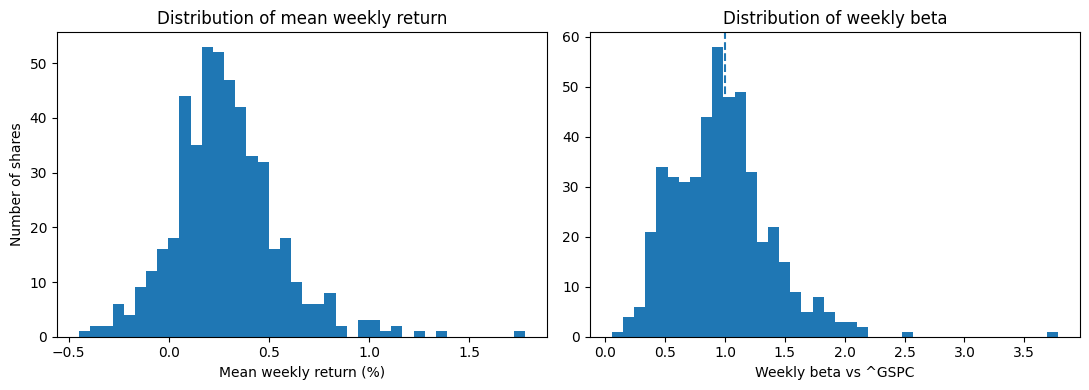

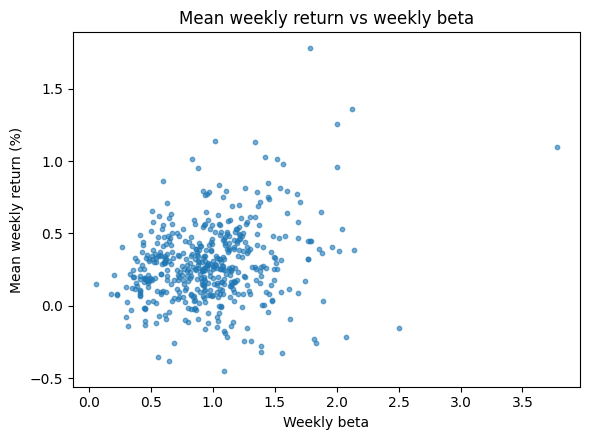

In [259]:
# Distribution of mean weekly return and beta
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(feat["mean_weekly_return"] * 100, bins=40)
ax[0].set_xlabel("Mean weekly return (%)"); ax[0].set_ylabel("Number of shares")
ax[0].set_title("Distribution of mean weekly return")
ax[1].hist(feat["weekly_beta"], bins=40)
ax[1].axvline(1, linestyle="--")
ax[1].set_xlabel("Weekly beta vs ^GSPC"); ax[1].set_title("Distribution of weekly beta")
plt.tight_layout()
plt.savefig("outputs/figures/fig_return_beta_distributions.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(feat["weekly_beta"], feat["mean_weekly_return"] * 100, s=10, alpha=0.6)
ax.set_xlabel("Weekly beta"); ax.set_ylabel("Mean weekly return (%)")
ax.set_title("Mean weekly return vs weekly beta")
plt.tight_layout()
plt.savefig("outputs/figures/fig_return_vs_beta.png", dpi=200)
plt.show()

## Task 1.4 Adapted RFM calculation


In [260]:
# Load clean data for the included shares
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs/figures", exist_ok=True)

def load_clean(name):
    return pd.read_csv(f"data/clean/{name}_valid.csv", index_col=0, parse_dates=True)

included = pd.read_csv("outputs/included_tickers.csv")["ticker"].tolist()
close = load_clean("close")[included]
vol = load_clean("volume")[included]

assert not close.isna().any().any() and not vol.isna().any().any(), "NaN found: re-check Step 2"
print("Shares:", len(included), "| sessions:", len(vol))

Shares: 486 | sessions: 1005


In [261]:
# Parameters, observation date and the 60-session window
BASELINE = 20      # preceding sessions used for the volume baseline (current day excluded)
WINDOW = 60        # latest sessions used for Frequency and Monetary
MULT = 2.0         # event if volume > MULT x baseline mean

obs_date = vol.index.max()                    # final common completed trading date in the study period
assert vol.loc[obs_date].notna().all()
last60 = vol.index[-WINDOW:]

print("Observation date:", obs_date.date())
print("60-session window:", last60[0].date(), "to", last60[-1].date())
print("First date an event can be tested (needs 20 prior sessions):", vol.index[BASELINE].date())
print("Sessions before the 60-session window:", len(vol) - WINDOW, "(must be >= 20)")

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31
First date an event can be tested (needs 20 prior sessions): 2021-02-02
Sessions before the 60-session window: 945 (must be >= 20)


In [262]:
# Rolling threshold and event flags, separately for every share and day
baseline_mean = vol.shift(1).rolling(BASELINE, min_periods=BASELINE).mean()
threshold = MULT * baseline_mean
event = vol > threshold                      # NaN threshold (first 20 sessions) gives False

event.to_csv("data/clean/high_volume_flags.csv")      # preserved, reproducible event flags
print("Total event flags:", int(event.sum().sum()))
print("Events per share (summary):")
print(event.sum().describe())

Total event flags: 18280
Events per share (summary):
count    486.000000
mean      37.613169
std        9.552813
min       15.000000
25%       31.000000
50%       37.000000
75%       44.000000
max       75.000000
dtype: float64


In [263]:
# Calculating R, F, M
last_event = pd.to_datetime(event.apply(lambda s: s.index[s].max() if s.any() else pd.NaT))
R = (obs_date - last_event).dt.days           # calendar days (weekends and holidays included); event on obs date gives 0
F = event.loc[last60].sum()                   # event days in the latest 60 sessions
M = (close * vol).loc[last60].sum()           # approximate traded value in USD

rfm = pd.DataFrame({
    "R": R, "F": F, "M": M,
    "last_event_date": last_event,
    "n_events_total": event.sum(),
})
rfm["rfm_valid"] = rfm["R"].notna()

print("Shares with NO event in valid history (R missing, excluded from RFM clustering):",
      int((~rfm["rfm_valid"]).sum()), rfm.index[~rfm["rfm_valid"]].tolist())
print("Shares with an event on the observation date (R = 0):", int((rfm["R"] == 0).sum()))
print("Shares with F = 0:", int((rfm["F"] == 0).sum()))

Shares with NO event in valid history (R missing, excluded from RFM clustering): 0 []
Shares with an event on the observation date (R = 0): 0
Shares with F = 0: 10


In [264]:
# Independent check, an explicit loop implementation for every share
def slow(t):
    v, c, d = vol[t].values, close[t].values, vol.index
    ev = [i for i in range(BASELINE, len(v)) if v[i] > MULT * v[i - BASELINE:i].mean()]
    r_ = (obs_date - d[ev[-1]]).days if ev else np.nan
    f_ = sum(1 for i in ev if i >= len(v) - WINDOW)
    m_ = float((c[-WINDOW:] * v[-WINDOW:]).sum())
    return r_, f_, m_

chk = pd.DataFrame({t: slow(t) for t in included}, index=["R", "F", "M"]).T
print("R matches:", np.allclose(chk["R"].fillna(-1), rfm["R"].fillna(-1)))
print("F matches:", (chk["F"] == rfm["F"]).all())
print("M matches:", np.allclose(chk["M"], rfm["M"]))

R matches: True
F matches: True
M matches: True


In [265]:
# Boundary tests on synthetic volume (evidence for threshold alignment)
def flag(v):
    s = pd.Series(v, dtype=float)
    return s > MULT * s.shift(1).rolling(BASELINE, min_periods=BASELINE).mean()

base = [1_000_000] * 20
assert flag(base + [2_500_000]).iloc[-1]            # brief example: qualifies
assert not flag(base + [1_800_000]).iloc[-1]        # brief example: does not qualify
assert not flag(base + [2_000_000]).iloc[-1]        # exactly 2x is NOT greater than 2x
assert not flag([1_000_000] * 19 + [9_000_000]).iloc[-1]   # only 19 prior sessions: not testable
# a spike raises the baseline of LATER days only (day tested is excluded from its own baseline):
# after a 5M spike the next baseline is (19 x 1M + 5M)/20 = 1.2M, so threshold = 2.4M
assert flag(base + [5_000_000, 2_500_000]).iloc[-1]
assert not flag(base + [5_000_000, 2_300_000]).iloc[-1]
print("All boundary tests passed")

All boundary tests passed


In [266]:
# Worked example for one share
ex = "AAPL" if "AAPL" in included else included[0]
d = pd.DataFrame({
    "close": close[ex], "volume": vol[ex],
    "baseline_mean_20": baseline_mean[ex], "threshold_2x": threshold[ex], "event": event[ex],
})
d["traded_value_usd"] = d["close"] * d["volume"]

print(f"--- {ex}: event days inside the 60-session window ---")
print(d.loc[last60].query("event").round(2))
print("\nLatest event in whole history:", rfm.loc[ex, "last_event_date"].date())
print(f"R = {obs_date.date()} - {rfm.loc[ex, 'last_event_date'].date()} = {rfm.loc[ex, 'R']:.0f} calendar days")
print(f"F = {rfm.loc[ex, 'F']:.0f} | M = ${rfm.loc[ex, 'M']:,.0f}")
print("Manual M:", f"${d.loc[last60, 'traded_value_usd'].sum():,.0f}")

--- AAPL: event days inside the 60-session window ---
             close     volume  baseline_mean_20  threshold_2x  event  \
Date                                                                   
2024-11-25  232.87   90152800        43820740.0    87641480.0   True   
2024-12-20  254.49  147495300        45004605.0    90009210.0   True   

            traded_value_usd  
Date                          
2024-11-25      2.099388e+10  
2024-12-20      3.753608e+10  

Latest event in whole history: 2024-12-20
R = 2024-12-31 - 2024-12-20 = 11 calendar days
F = 2 | M = $623,303,377,707
Manual M: $623,303,377,707


            R       F             M  log1p_M
count  486.00  486.00  4.860000e+02   486.00
mean    20.41    2.99  3.940419e+10    23.68
std     21.34    1.33  1.291388e+11     0.94
min      4.00    0.00  1.297483e+09    20.98
25%     11.00    2.00  1.019517e+10    23.05
50%     11.00    3.00  1.668382e+10    23.54
75%     14.75    4.00  3.227689e+10    24.20
max    222.00    8.00  1.847697e+12    28.24

Skewness:
 R           3.65
F           0.42
M          11.68
log1p_M     1.08
dtype: float64

Most common R values (shares bunching on the same event date?):
R
11    353
36     17
55     11
60      6
46      6
25      5
Name: count, dtype: int64

Dates in the window with the highest share of stocks flagged:
Date
2024-12-20    72.8
2024-11-06    32.1
2024-10-31    17.1
2024-11-25    15.6
2024-10-30     9.5
Name: % of shares flagged, dtype: float64


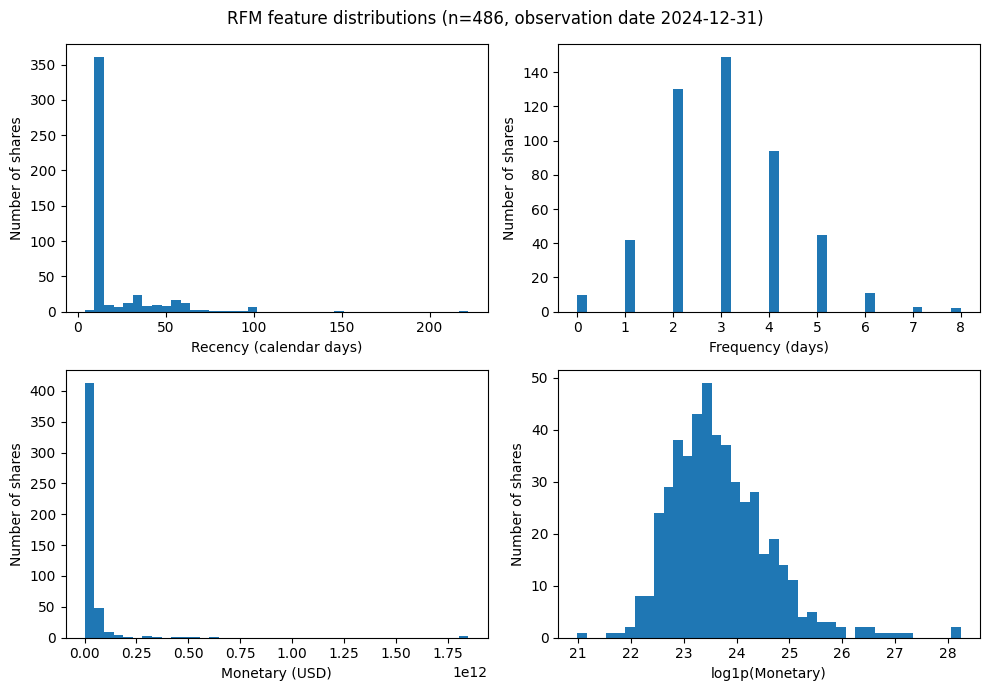

In [267]:
# Summaries, skew and market wide event timing
valid = rfm[rfm["rfm_valid"]].copy()
valid["log1p_M"] = np.log1p(valid["M"])

print(valid[["R", "F", "M", "log1p_M"]].describe().round(2))
print("\nSkewness:\n", valid[["R", "F", "M", "log1p_M"]].skew().round(2))

print("\nMost common R values (shares bunching on the same event date?):")
print(valid["R"].value_counts().head(6))

share_with_event = event.loc[last60].mean(axis=1).sort_values(ascending=False)
print("\nDates in the window with the highest share of stocks flagged:")
print((share_with_event.head(5) * 100).round(1).rename("% of shares flagged"))

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, col, lab in zip(ax.ravel(), ["R", "F", "M", "log1p_M"],
                       ["Recency (calendar days)", "Frequency (days)", "Monetary (USD)", "log1p(Monetary)"]):
    a.hist(valid[col], bins=40)
    a.set_xlabel(lab); a.set_ylabel("Number of shares")
fig.suptitle(f"RFM feature distributions (n={len(valid)}, observation date {obs_date.date()})")
plt.tight_layout()
plt.savefig("outputs/figures/fig_rfm_distributions.png", dpi=200)
plt.show()

In [268]:
risk = pd.read_csv("outputs/feature_table_risk_return.csv", index_col=0)
full = risk.join(rfm)
full.to_csv("outputs/feature_table_all.csv")

common = full[full["rfm_valid"]]
common.index.to_series().to_csv("outputs/common_valid_shares.csv", index=False)
print("Shares with risk/return features:", len(full), "| with valid RFM (common set):", len(common))

meta = {
    "observation_date": str(obs_date.date()),
    "window_first_session": str(last60[0].date()),
    "window_sessions": WINDOW, "baseline_sessions": BASELINE, "threshold_multiplier": MULT,
    "event_rule": "volume > 2 x mean volume of preceding 20 sessions (current day excluded), strict inequality",
    "recency_basis": "calendar days to latest event in whole valid history",
    "n_shares_rfm_valid": int(len(common)),
    "calculation_version": "v1",
}
json.dump(meta, open("outputs/rfm_metadata.json", "w"), indent=2)
print(json.dumps(meta, indent=2))

Shares with risk/return features: 486 | with valid RFM (common set): 486
{
  "observation_date": "2024-12-31",
  "window_first_session": "2024-10-07",
  "window_sessions": 60,
  "baseline_sessions": 20,
  "threshold_multiplier": 2.0,
  "event_rule": "volume > 2 x mean volume of preceding 20 sessions (current day excluded), strict inequality",
  "recency_basis": "calendar days to latest event in whole valid history",
  "n_shares_rfm_valid": 486,
  "calculation_version": "v1"
}


## Task 2.1 Feature preparation

In [269]:
# Load and define the common share set
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

os.makedirs("outputs/figures", exist_ok=True)

full = pd.read_csv("outputs/feature_table_all.csv", index_col=0)
need = ["mean_weekly_return", "weekly_beta", "R", "F", "M"]

common = full.dropna(subset=need)
common = common[common["rfm_valid"].astype(bool)].copy()
print("Shares with all features (common set):", len(common), "of", len(full))

Shares with all features (common set): 486 of 486


In [270]:
# Skew and outlier diagnostics on the raw features
raw = common[need].copy()
raw["log1p_M"] = np.log1p(raw["M"])
raw["log1p_R"] = np.log1p(raw["R"])      # diagnostic only, unless you set LOG_R = True below

def diagnostics(df):
    q1, q3 = df.quantile(0.25), df.quantile(0.75)
    iqr = q3 - q1
    z = (df - df.mean()) / df.std(ddof=0)
    top5_share = (z ** 2).apply(lambda s: s.nlargest(5).sum() / s.sum())   # share of total variance from the 5 most extreme shares
    return pd.DataFrame({
        "mean": df.mean(), "median": df.median(),
        "skew": df.skew(), "excess_kurtosis": df.kurt(),
        "n_outliers_IQR": ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum(),
        "n_abs_z_gt_3": (z.abs() > 3).sum(),
        "max_abs_z": z.abs().max(),
        "top5_share_of_variance": top5_share,
    })

diag = diagnostics(raw)
print(diag.round(3).to_string())
diag.round(4).to_csv("outputs/feature_diagnostics.csv")

                            mean        median    skew  excess_kurtosis  n_outliers_IQR  n_abs_z_gt_3  max_abs_z  top5_share_of_variance
mean_weekly_return  3.000000e-03  3.000000e-03   0.868            3.019              15             6      5.631                   0.169
weekly_beta         9.740000e-01  9.510000e-01   1.104            4.471              10             2      6.893                   0.175
R                   2.040700e+01  1.100000e+01   3.646           21.004             115            11      9.455                   0.352
F                   2.990000e+00  3.000000e+00   0.425            0.545               2             5      3.769                   0.115
M                   3.940419e+10  1.668382e+10  11.684          155.513              45             5     14.017                   0.894
log1p_M             2.368200e+01  2.353800e+01   1.079            2.691              13             7      4.848                   0.174
log1p_R             2.809000e+00  2.48500

In [271]:
# Naming the most extreme shares
for col in ["weekly_beta", "mean_weekly_return", "M", "R"]:
    z = ((common[col] - common[col].mean()) / common[col].std(ddof=0)).abs()
    print(f"\nMost extreme on {col}:")
    print(common.loc[z.nlargest(5).index, ["company", "sector", col]].to_string())


Most extreme on weekly_beta:
             company                  sector  weekly_beta
CVNA         Carvana  Consumer Discretionary     3.778560
XYZ      Block, Inc.              Financials     2.504520
COHR  Coherent Corp.  Information Technology     2.139305
NVDA          Nvidia  Information Technology     2.125953
TWLO          Twilio  Information Technology     2.073379

Most extreme on mean_weekly_return:
                  company                  sector  mean_weekly_return
SMCI           Supermicro  Information Technology            0.017772
NVDA               Nvidia  Information Technology            0.013624
VRT                Vertiv             Industrials            0.012583
VST          Vistra Corp.               Utilities            0.011395
FIX   Comfort Systems USA             Industrials            0.011297

Most extreme on M:
          company                  sector             M
TSLA  Tesla, Inc.  Consumer Discretionary  1.847697e+12
NVDA       Nvidia  Information Te

In [272]:
# Building the two matrices, standardise each separately
LOG_R = False

X_rr_raw = common[["mean_weekly_return", "weekly_beta"]].copy()

X_act_raw = pd.DataFrame({"R": common["R"], "F": common["F"], "log1p_M": np.log1p(common["M"])})
if LOG_R:
    X_act_raw["R"] = np.log1p(X_act_raw["R"])
    X_act_raw = X_act_raw.rename(columns={"R": "log1p_R"})

assert X_rr_raw.index.equals(X_act_raw.index)        # identical shares in both matrices
assert not X_rr_raw.isna().any().any() and not X_act_raw.isna().any().any()

sc_rr, sc_act = StandardScaler(), StandardScaler()   # fitted separately, one per matrix
X_rr = pd.DataFrame(sc_rr.fit_transform(X_rr_raw), index=X_rr_raw.index, columns=X_rr_raw.columns)
X_act = pd.DataFrame(sc_act.fit_transform(X_act_raw), index=X_act_raw.index, columns=X_act_raw.columns)

print("Standardised means (should be ~0):\n", X_rr.mean().round(10).to_dict(), X_act.mean().round(10).to_dict())
print("Standardised std (should be 1):\n", X_rr.std(ddof=0).round(6).to_dict(), X_act.std(ddof=0).round(6).to_dict())

common.to_csv("outputs/features_common_set_original_units.csv")
X_rr.to_csv("outputs/X_riskreturn_scaled.csv")
X_act.to_csv("outputs/X_activity_scaled.csv")
X_rr_raw.to_csv("outputs/X_riskreturn_raw.csv")
X_act_raw.to_csv("outputs/X_activity_raw.csv")

Standardised means (should be ~0):
 {'mean_weekly_return': -0.0, 'weekly_beta': -0.0} {'R': -0.0, 'F': -0.0, 'log1p_M': -0.0}
Standardised std (should be 1):
 {'mean_weekly_return': 1.0, 'weekly_beta': 1.0} {'R': 1.0, 'F': 1.0, 'log1p_M': 1.0}


In [273]:
# Showing how the transformation changes distances
cmp = pd.DataFrame({
    "M raw": diagnostics(raw[["M"]]).iloc[0],
    "log1p(M)": diagnostics(raw[["log1p_M"]]).iloc[0],
    "R raw": diagnostics(raw[["R"]]).iloc[0],
    "log1p(R)": diagnostics(raw[["log1p_R"]]).iloc[0],
}).T[["skew", "n_abs_z_gt_3", "max_abs_z", "top5_share_of_variance"]]
print(cmp.round(3).to_string())
print("\nReading guide: after standardisation every feature has variance 1, but if the top 5 shares hold a large")
print("share of that variance, distances (and so clusters) are being driven by a handful of shares.")

            skew  n_abs_z_gt_3  max_abs_z  top5_share_of_variance
M raw     11.684           5.0     14.017                   0.894
log1p(M)   1.079           7.0      4.848                   0.174
R raw      3.646          11.0      9.455                   0.352
log1p(R)   1.583           2.0      4.216                   0.117

Reading guide: after standardisation every feature has variance 1, but if the top 5 shares hold a large
share of that variance, distances (and so clusters) are being driven by a handful of shares.


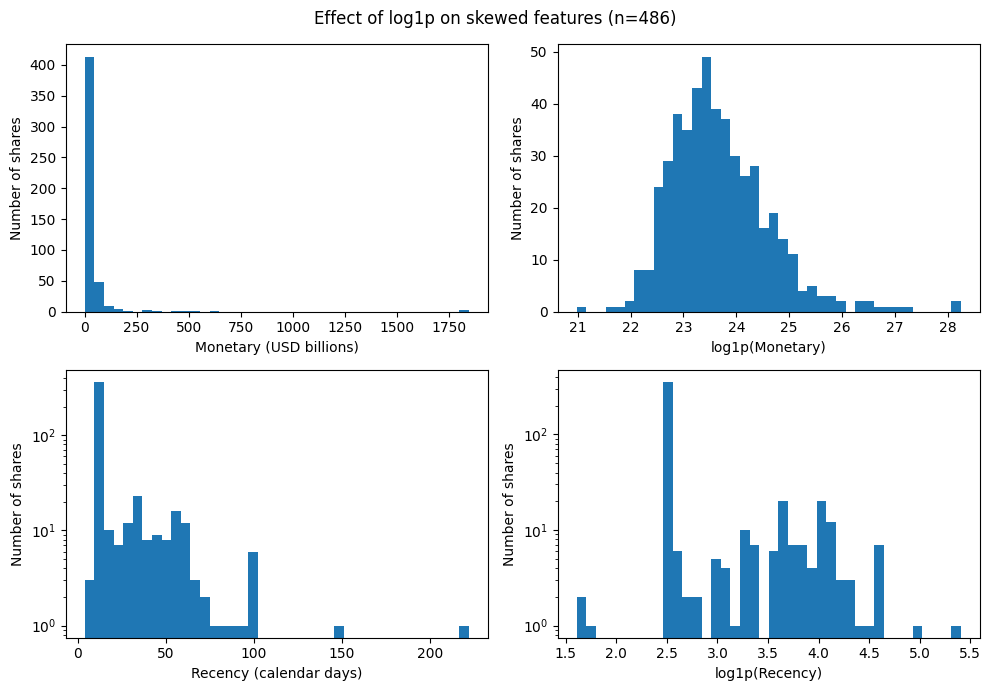

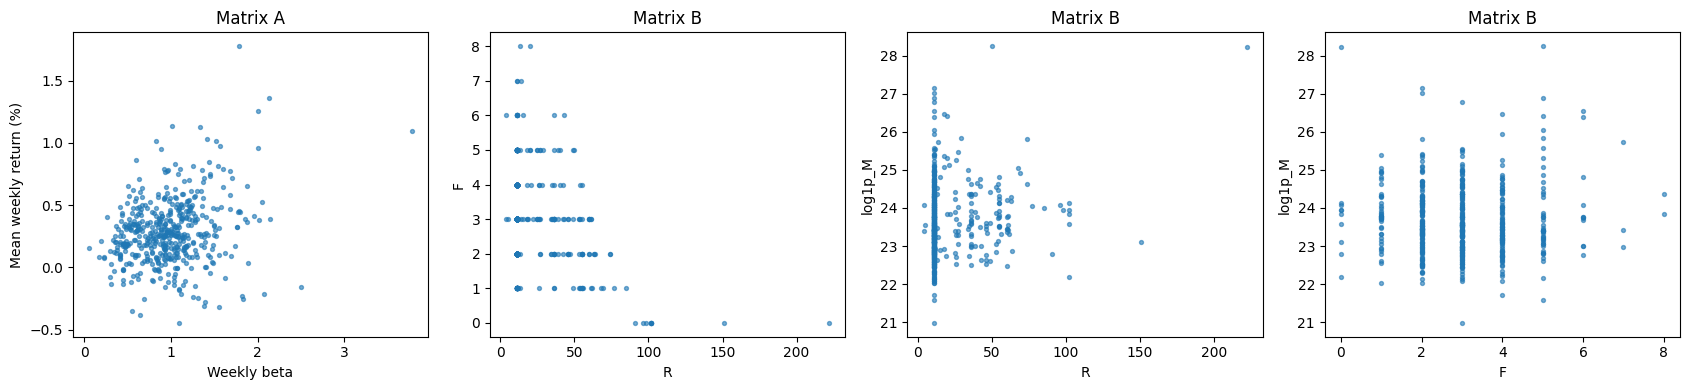

In [274]:
# Skewed features and matrix figures
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
ax[0, 0].hist(raw["M"] / 1e9, bins=40);      ax[0, 0].set_xlabel("Monetary (USD billions)")
ax[0, 1].hist(raw["log1p_M"], bins=40);      ax[0, 1].set_xlabel("log1p(Monetary)")
ax[1, 0].hist(raw["R"], bins=40);            ax[1, 0].set_xlabel("Recency (calendar days)"); ax[1, 0].set_yscale("log")
ax[1, 1].hist(raw["log1p_R"], bins=40);      ax[1, 1].set_xlabel("log1p(Recency)"); ax[1, 1].set_yscale("log")
for a in ax.ravel():
    a.set_ylabel("Number of shares")
fig.suptitle(f"Effect of log1p on skewed features (n={len(common)})")
plt.tight_layout()
plt.savefig("outputs/figures/fig_transform_effect.png", dpi=200)
plt.show()

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
ax[0].scatter(X_rr_raw["weekly_beta"], X_rr_raw["mean_weekly_return"] * 100, s=8, alpha=0.6)
ax[0].set_xlabel("Weekly beta"); ax[0].set_ylabel("Mean weekly return (%)"); ax[0].set_title("Matrix A")
pairs = [("R", "F"), ("R", "log1p_M"), ("F", "log1p_M")]
for a, (x, y) in zip(ax[1:], pairs):
    xc = x if x in X_act_raw else "log1p_R"
    a.scatter(X_act_raw[xc], X_act_raw[y], s=8, alpha=0.6)
    a.set_xlabel(xc); a.set_ylabel(y); a.set_title("Matrix B")
plt.tight_layout()
plt.savefig("outputs/figures/fig_matrix_scatter.png", dpi=200)
plt.show()

In [275]:
# Preparation metadata for reproducibility
meta = {
    "n_shares_common_set": int(len(common)),
    "matrix_A_features": list(X_rr.columns),
    "matrix_B_features": list(X_act.columns),
    "log1p_applied_to": ["M"] + (["R"] if LOG_R else []),
    "scaler": "sklearn StandardScaler (mean 0, population std 1), fitted separately per matrix",
    "matrix_A_means": {k: float(v) for k, v in zip(X_rr.columns, sc_rr.mean_)},
    "matrix_A_stds": {k: float(v) for k, v in zip(X_rr.columns, sc_rr.scale_)},
    "matrix_B_means": {k: float(v) for k, v in zip(X_act.columns, sc_act.mean_)},
    "matrix_B_stds": {k: float(v) for k, v in zip(X_act.columns, sc_act.scale_)},
    "outliers": "retained (real observations); influence quantified in feature_diagnostics.csv",
    "calculation_version": "v1",
}
json.dump(meta, open("outputs/feature_preparation_metadata.json", "w"), indent=2)
print(json.dumps(meta, indent=2))

{
  "n_shares_common_set": 486,
  "matrix_A_features": [
    "mean_weekly_return",
    "weekly_beta"
  ],
  "matrix_B_features": [
    "R",
    "F",
    "log1p_M"
  ],
  "log1p_applied_to": [
    "M"
  ],
  "scaler": "sklearn StandardScaler (mean 0, population std 1), fitted separately per matrix",
  "matrix_A_means": {
    "mean_weekly_return": 0.0028571730962930753,
    "weekly_beta": 0.9736952952325375
  },
  "matrix_A_stds": {
    "mean_weekly_return": 0.002648879294169404,
    "weekly_beta": 0.40691963135438625
  },
  "matrix_B_means": {
    "R": 20.40740740740741,
    "F": 2.9897119341563787,
    "log1p_M": 23.68212456183186
  },
  "matrix_B_stds": {
    "R": 21.32046937255646,
    "F": 1.3294299032424965,
    "log1p_M": 0.9412334803637373
  },
  "outliers": "retained (real observations); influence quantified in feature_diagnostics.csv",
  "calculation_version": "v1"
}


## Tasks 2.2 and 2.3 Ward and K-means clustering


In [276]:
# Load scaled matrices and original unit features
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED = 42            # fixed random seed
N_INIT = 50          # K-means initialisations per fit (best inertia kept)
KS = list(range(2, 9))
os.makedirs("outputs/figures", exist_ok=True)

X = {"rr": pd.read_csv("outputs/X_riskreturn_scaled.csv", index_col=0),
     "act": pd.read_csv("outputs/X_activity_scaled.csv", index_col=0)}
NAMES = {"rr": "Risk and return", "act": "Trading activity (RFM)"}
orig = pd.read_csv("outputs/features_common_set_original_units.csv", index_col=0)

assert X["rr"].index.equals(X["act"].index) and X["rr"].index.equals(orig.index)
print("Shares:", len(orig), "| features A:", list(X["rr"].columns), "| features B:", list(X["act"].columns))

Shares: 486 | features A: ['mean_weekly_return', 'weekly_beta'] | features B: ['R', 'F', 'log1p_M']


In [277]:
# Ward linkage (Euclidean) and diagnostics
Z = {m: linkage(X[m].values, method="ward", metric="euclidean") for m in X}

def ward_labels(Xm, k):
    # Ward linkage only supports Euclidean distance
    return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xm)

def size_info(lab):
    s = np.sort(np.bincount(lab))[::-1]
    return {"sizes": s.tolist(), "min_size": int(s.min()), "max_size": int(s.max()),
            "n_clusters_below_5": int((s < 5).sum())}

rows = []
for m in X:
    for k in KS:
        lab = ward_labels(X[m].values, k)
        # consistency check: sklearn labels must equal SciPy's cut of the same tree (ARI = 1)
        assert adjusted_rand_score(lab, fcluster(Z[m], k, criterion="maxclust")) == 1.0
        rows.append({"matrix": m, "algorithm": "ward", "k": k,
                     "silhouette": silhouette_score(X[m].values, lab), **size_info(lab)})
ward_diag = pd.DataFrame(rows)
ward_diag.to_csv("outputs/clustering_diagnostics_ward.csv", index=False)
print("sklearn and SciPy Ward cuts agree for all k")
for m in X:
    print(f"\nWARD: {NAMES[m]}")
    print(ward_diag[ward_diag.matrix == m][["k", "silhouette", "min_size", "max_size", "n_clusters_below_5", "sizes"]].round(3).to_string(index=False))

sklearn and SciPy Ward cuts agree for all k

WARD: Risk and return
 k  silhouette  min_size  max_size  n_clusters_below_5                            sizes
 2       0.339        92       394                   0                        [394, 92]
 3       0.274        92       230                   0                   [230, 164, 92]
 4       0.282        48       182                   0               [182, 164, 92, 48]
 5       0.304        48       182                   0            [182, 98, 92, 66, 48]
 6       0.320         5       182                   0         [182, 98, 87, 66, 48, 5]
 7       0.324         5       160                   0     [160, 98, 87, 66, 48, 22, 5]
 8       0.321         5       160                   0 [160, 98, 66, 56, 48, 31, 22, 5]

WARD: Trading activity (RFM)
 k  silhouette  min_size  max_size  n_clusters_below_5                             sizes
 2       0.368        82       404                   0                         [404, 82]
 3       0.304       

In [278]:
# K-means diagnostics, including initialisation stability
rows = []
for m in X:
    Xm = X[m].values
    for k in KS:
        best = KMeans(n_clusters=k, init="k-means++", n_init=N_INIT, random_state=SEED).fit(Xm)
        singles = [KMeans(n_clusters=k, init="k-means++", n_init=1, random_state=s).fit(Xm) for s in range(100, 120)]
        inert = np.array([s.inertia_ for s in singles])
        rows.append({
            "matrix": m, "algorithm": "kmeans", "k": k,
            "silhouette": silhouette_score(Xm, best.labels_),
            "inertia": best.inertia_,
            "single_init_inertia_max_vs_best_pct": 100 * (inert.max() / best.inertia_ - 1),
            "share_single_runs_reaching_best": float(np.mean(np.isclose(inert, best.inertia_, rtol=1e-6))),
            "mean_ARI_single_vs_best": float(np.mean([adjusted_rand_score(best.labels_, s.labels_) for s in singles])),
            **size_info(best.labels_),
        })
km_diag = pd.DataFrame(rows)
km_diag.to_csv("outputs/clustering_diagnostics_kmeans.csv", index=False)
for m in X:
    print(f"\nK-MEANS: {NAMES[m]}")
    print(km_diag[km_diag.matrix == m][["k", "silhouette", "inertia", "min_size", "max_size",
          "share_single_runs_reaching_best", "mean_ARI_single_vs_best", "sizes"]].round(3).to_string(index=False))


K-MEANS: Risk and return
 k  silhouette  inertia  min_size  max_size  share_single_runs_reaching_best  mean_ARI_single_vs_best                            sizes
 2       0.387  621.634       143       343                             1.00                    1.000                       [343, 143]
 3       0.329  461.179       119       202                             0.35                    0.957                  [202, 165, 119]
 4       0.326  371.571        41       160                             0.00                    0.695              [160, 153, 132, 41]
 5       0.338  309.960        28       165                             0.00                    0.568          [165, 124, 114, 55, 28]
 6       0.326  265.707        20       134                             0.00                    0.485       [134, 115, 85, 76, 56, 20]
 7       0.329  227.239         5       126                             0.00                    0.492    [126, 105, 84, 78, 47, 41, 5]
 8       0.354  194.249      

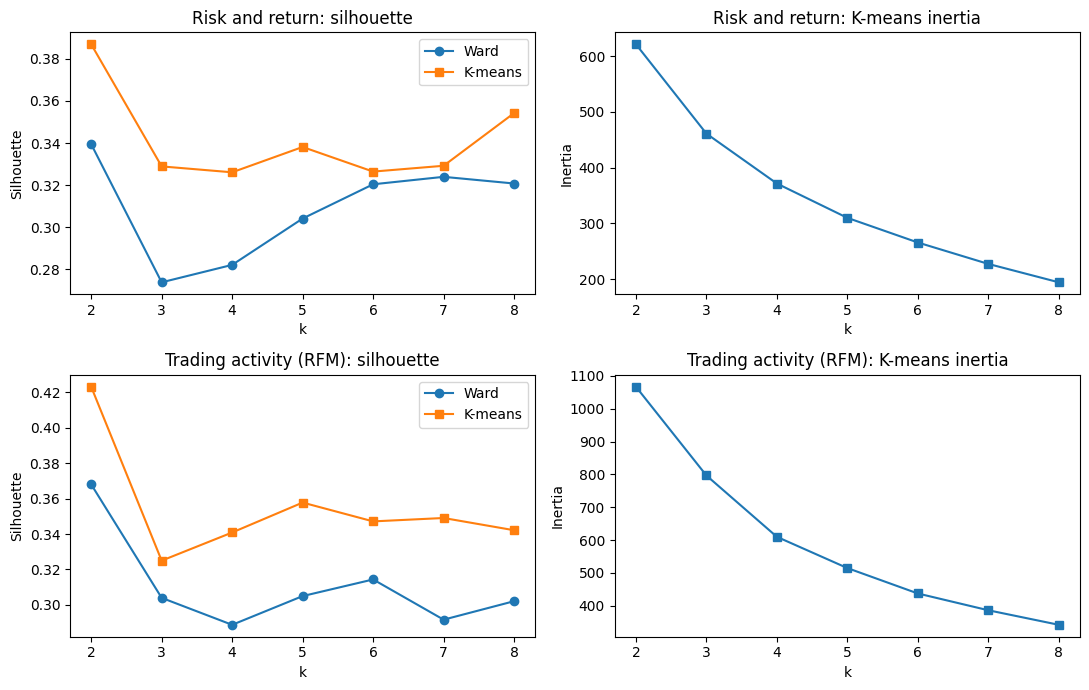

In [279]:
# Silhouette and inertia plots
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for i, m in enumerate(X):
    w, k_ = ward_diag[ward_diag.matrix == m], km_diag[km_diag.matrix == m]
    ax[i, 0].plot(w.k, w.silhouette, marker="o", label="Ward")
    ax[i, 0].plot(k_.k, k_.silhouette, marker="s", label="K-means")
    ax[i, 0].set_title(f"{NAMES[m]}: silhouette"); ax[i, 0].set_xlabel("k"); ax[i, 0].set_ylabel("Silhouette"); ax[i, 0].legend()
    ax[i, 1].plot(k_.k, k_.inertia, marker="s")
    ax[i, 1].set_title(f"{NAMES[m]}: K-means inertia"); ax[i, 1].set_xlabel("k"); ax[i, 1].set_ylabel("Inertia")
plt.tight_layout()
plt.savefig("outputs/figures/fig_k_diagnostics.png", dpi=200)
plt.show()

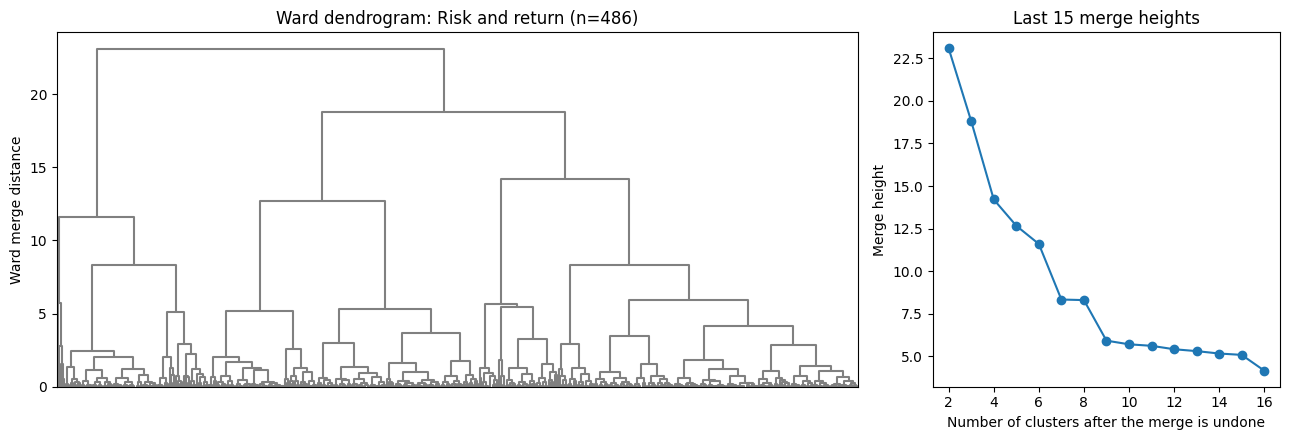

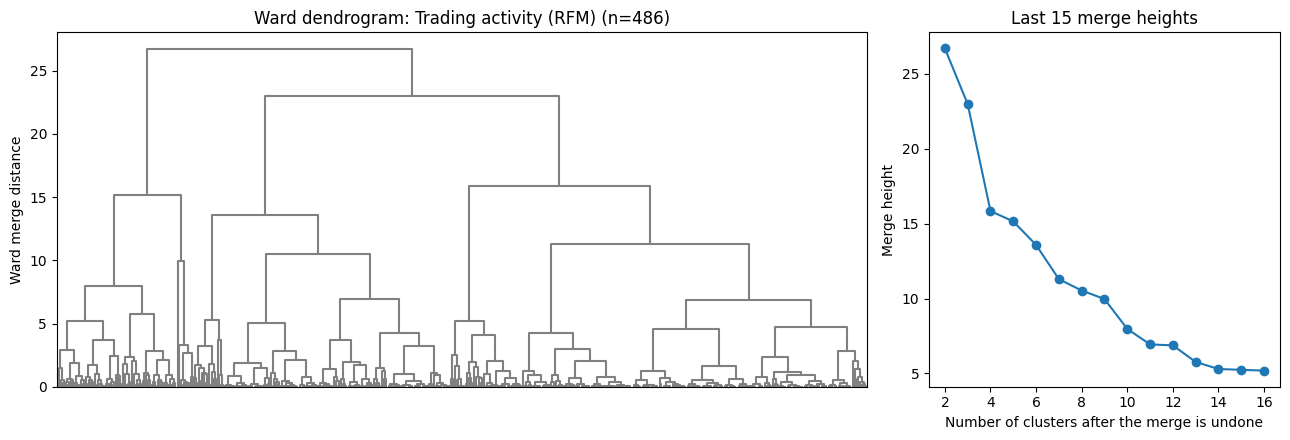

In [280]:
# Dendrograms (one per matrix) with merge heights
def plot_dendrogram(m, k=None):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 1.3]})
    dendrogram(Z[m], no_labels=True, color_threshold=0, above_threshold_color="gray", ax=ax[0])
    ax[0].set_title(f"Ward dendrogram: {NAMES[m]} (n={len(X[m])})")
    ax[0].set_ylabel("Ward merge distance")
    if k:
        cut = (Z[m][-(k - 1), 2] + Z[m][-k, 2]) / 2        # height that yields exactly k clusters
        ax[0].axhline(cut, linestyle="--", color="red")
        ax[0].text(0.01, cut, f" k={k}", color="red", va="bottom", transform=ax[0].get_yaxis_transform())
    h = Z[m][-15:, 2][::-1]
    ax[1].plot(range(2, 2 + len(h)), h, marker="o")
    ax[1].set_xlabel("Number of clusters after the merge is undone"); ax[1].set_ylabel("Merge height")
    ax[1].set_title("Last 15 merge heights")
    plt.tight_layout()
    plt.savefig(f"outputs/figures/fig_dendrogram_{m}.png", dpi=200)
    plt.show()

for m in X:
    plot_dendrogram(m)

In [281]:
# Preview profiles (original units, medians) for any k you are considering
def profile(labels, cols=("mean_weekly_return", "weekly_beta", "R", "F", "M")):
    d = orig[list(cols)].copy()
    d["cluster"] = labels
    g = d.groupby("cluster")
    return pd.concat([g.size().rename("n"), g.median().add_suffix("_median")], axis=1)

# example: look at several candidate k for the activity matrix with Ward
for k in (3, 4, 5):
    print(f"\nActivity matrix, Ward, k={k}")
    print(profile(ward_labels(X["act"].values, k)).round(4).to_string())


Activity matrix, Ward, k=3
           n  mean_weekly_return_median  weekly_beta_median  R_median  F_median      M_median
cluster                                                                                      
0        250                     0.0025              0.9274      11.0       3.0  1.117761e+10
1         82                     0.0024              1.0466      54.5       2.0  1.784903e+10
2        154                     0.0033              0.9886      11.0       3.0  3.969545e+10

Activity matrix, Ward, k=4
           n  mean_weekly_return_median  weekly_beta_median  R_median  F_median      M_median
cluster                                                                                      
0         82                     0.0024              1.0466      54.5       2.0  1.784903e+10
1        207                     0.0024              0.9239      11.0       3.0  1.078527e+10
2        154                     0.0033              0.9886      11.0       3.0  3.969545e+10
3   

In [282]:
K_CHOICE = {"rr_ward": 5, "rr_kmeans": 5, "act_ward": 5, "act_kmeans": 5}
assert all(v is not None for v in K_CHOICE.values()), "Set K_CHOICE in cell 7 first"


rr_ward  (k=5)
           n  mean_weekly_return_median  weekly_beta_median  R_median  F_median      M_median
cluster                                                                                      
0        182                     0.0017              0.9644      11.0       3.0  1.298483e+10
1         98                     0.0039              0.6663      11.0       3.0  1.764940e+10
2         92                     0.0055              1.2177      11.0       3.0  2.418413e+10
3         66                     0.0011              0.4485      11.0       3.0  1.770109e+10
4         48                     0.0025              1.5139      11.0       3.0  2.869761e+10

rr_kmeans  (k=5)
           n  mean_weekly_return_median  weekly_beta_median  R_median  F_median      M_median
cluster                                                                                      
0        165                     0.0042              0.9994      11.0       3.0  1.769899e+10
1        124              

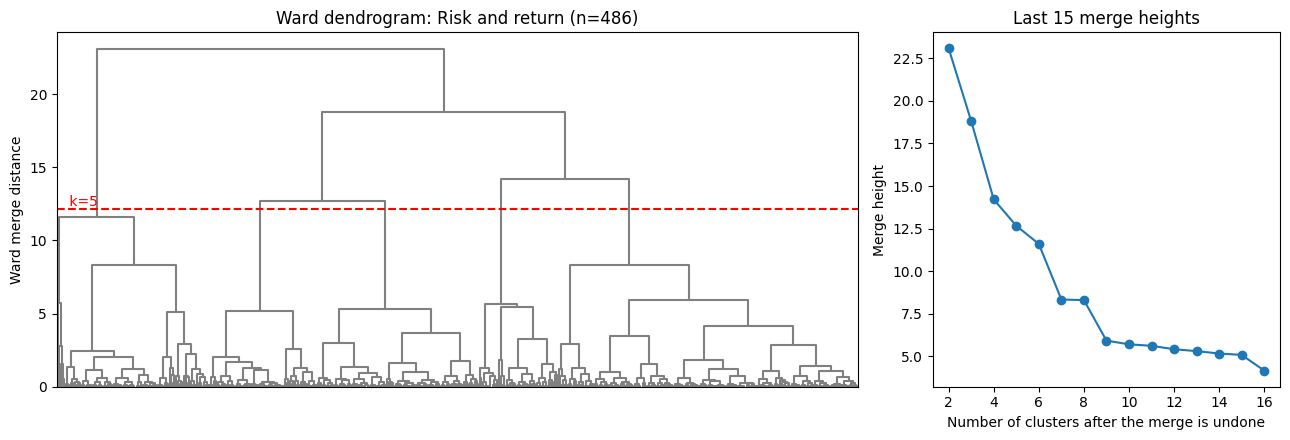

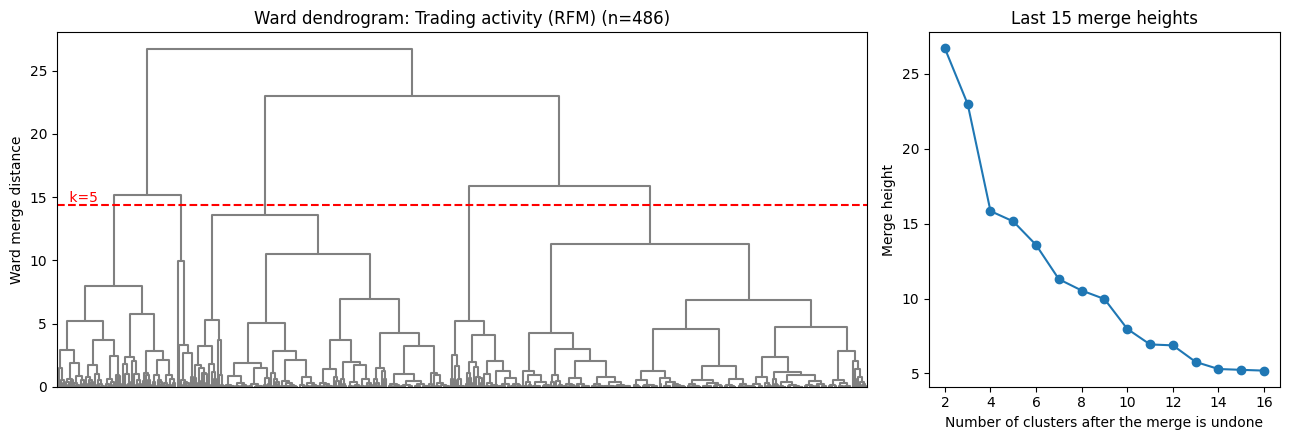

In [283]:
# Fit the four baseline solutions, save assignments and profiles
def relabel_by_size(lab):
    """Arbitrary cluster numbers are replaced by size rank (0 = largest cluster) for readability only."""
    order = pd.Series(lab).value_counts().index
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping[v] for v in lab])

assign = pd.DataFrame(index=orig.index)
for m in X:
    assign[f"{m}_ward"] = relabel_by_size(ward_labels(X[m].values, K_CHOICE[f"{m}_ward"]))
    km = KMeans(n_clusters=K_CHOICE[f"{m}_kmeans"], init="k-means++", n_init=N_INIT, random_state=SEED).fit(X[m].values)
    assign[f"{m}_kmeans"] = relabel_by_size(km.labels_)

out = orig[["company", "sector", "mean_weekly_return", "weekly_beta", "R", "F", "M"]].join(assign)
out.to_csv("outputs/cluster_assignments_baseline.csv")

for col in assign.columns:
    print(f"\n{col}  (k={assign[col].nunique()})")
    print(profile(assign[col].values).round(4).to_string())

print("\nAgreement between algorithms on the same shares (adjusted Rand index):")
for m in X:
    print(f"  {NAMES[m]}: {adjusted_rand_score(assign[f'{m}_ward'], assign[f'{m}_kmeans']):.3f}")

for m in X:
    plot_dendrogram(m, k=K_CHOICE[f"{m}_ward"])      # redraw with the chosen cut shown

json.dump({"seed": SEED, "n_init": N_INIT, "k_range": KS, "K_CHOICE": K_CHOICE,
           "ward": "scipy/sklearn Ward linkage, Euclidean distance, standardised features",
           "label_convention": "cluster numbers ranked by size, 0 = largest",
           "calculation_version": "v1"},
          open("outputs/clustering_metadata.json", "w"), indent=2)

## Task 2.4 Cluster profiles and algorithm comparison


In [284]:
# Load assignments, scaled matrices and original unit features
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from scipy.optimize import linear_sum_assignment

os.makedirs("outputs/figures", exist_ok=True)

out = pd.read_csv("outputs/cluster_assignments_baseline.csv", index_col=0)
Xs = {"rr": pd.read_csv("outputs/X_riskreturn_scaled.csv", index_col=0),
      "act": pd.read_csv("outputs/X_activity_scaled.csv", index_col=0)}
NAMES = {"rr": "Risk and return", "act": "Trading activity (RFM)"}
SOL = ["rr_ward", "rr_kmeans", "act_ward", "act_kmeans"]
TITLE = {"rr_ward": "Risk and return: Ward", "rr_kmeans": "Risk and return: K-means",
         "act_ward": "Trading activity: Ward", "act_kmeans": "Trading activity: K-means"}

assert out.index.equals(Xs["rr"].index) and out.index.equals(Xs["act"].index)   # same shares everywhere

# readable original units
out["M_bn"] = out["M"] / 1e9                               # USD billions over the 60 sessions
out["mean_weekly_return_pct"] = out["mean_weekly_return"] * 100
FEATS = {"rr": ["mean_weekly_return_pct", "weekly_beta"], "act": ["R", "F", "M_bn"]}
print("Shares:", len(out), "| solutions:", {c: int(out[c].nunique()) for c in SOL})

Shares: 486 | solutions: {'rr_ward': 5, 'rr_kmeans': 5, 'act_ward': 5, 'act_kmeans': 5}


In [285]:
# Profiles in ORIGINAL units (means, medians, and median relative to the overall median)
def profile_table(col):
    f = FEATS[col.split("_")[0]]
    g = out.groupby(col)[f]
    tab = pd.concat([g.size().rename("n"), g.mean().add_suffix("_mean"), g.median().add_suffix("_median")], axis=1)
    rel = (g.median() / out[f].median()).add_suffix("_median_vs_overall")   # 1.0 = same as the whole sample
    return pd.concat([tab, rel], axis=1)

all_profiles = []
for col in SOL:
    t = profile_table(col)
    print(f"\n{TITLE[col]} (k={len(t)})")
    print(t.round(3).to_string())
    all_profiles.append(t.assign(solution=col).reset_index().rename(columns={col: "cluster"}))
pd.concat(all_profiles).to_csv("outputs/cluster_profiles_original_units.csv", index=False)


Risk and return: Ward (k=5)
           n  mean_weekly_return_pct_mean  weekly_beta_mean  mean_weekly_return_pct_median  weekly_beta_median  mean_weekly_return_pct_median_vs_overall  weekly_beta_median_vs_overall
rr_ward                                                                                                                                                                                
0        182                        0.132             0.973                          0.166               0.964                                     0.634                          1.015
1         98                        0.422             0.710                          0.392               0.666                                     1.495                          0.701
2         92                        0.632             1.298                          0.550               1.218                                     2.101                          1.281
3         66                        0.088          

In [286]:
# Who is in each cluster? (helps you label clusters, and explains tiny ones)
for col in SOL:
    print(f"\n{TITLE[col]}")
    for c, d in out.groupby(col):
        line = f"  C{c} (n={len(d)}): top sectors {d['sector'].value_counts().head(2).to_dict()} | largest M: {d.nlargest(3, 'M_bn').index.tolist()}"
        if len(d) <= 15:
            line += f" | ALL members: {d.index.tolist()}"
        print(line)


Risk and return: Ward
  C0 (n=182): top sectors {'Industrials': 40, 'Financials': 26} | largest M: ['BA', 'V', 'INTC']
  C1 (n=98): top sectors {'Financials': 28, 'Energy': 16} | largest M: ['JPM', 'BRK-B', 'COST']
  C2 (n=92): top sectors {'Information Technology': 29, 'Industrials': 21} | largest M: ['NVDA', 'AAPL', 'MSFT']
  C3 (n=66): top sectors {'Consumer Staples': 22, 'Health Care': 19} | largest M: ['UNH', 'PFE', 'PG']
  C4 (n=48): top sectors {'Information Technology': 23, 'Consumer Discretionary': 10} | largest M: ['TSLA', 'AMZN', 'AMD']

Risk and return: K-means
  C0 (n=165): top sectors {'Financials': 37, 'Industrials': 34} | largest M: ['AAPL', 'MSFT', 'META']
  C1 (n=124): top sectors {'Utilities': 25, 'Consumer Staples': 23} | largest M: ['UNH', 'BRK-B', 'WMT']
  C2 (n=114): top sectors {'Health Care': 24, 'Industrials': 22} | largest M: ['BA', 'INTC', 'TXN']
  C3 (n=55): top sectors {'Information Technology': 27, 'Consumer Discretionary': 11} | largest M: ['TSLA', 'AMZ

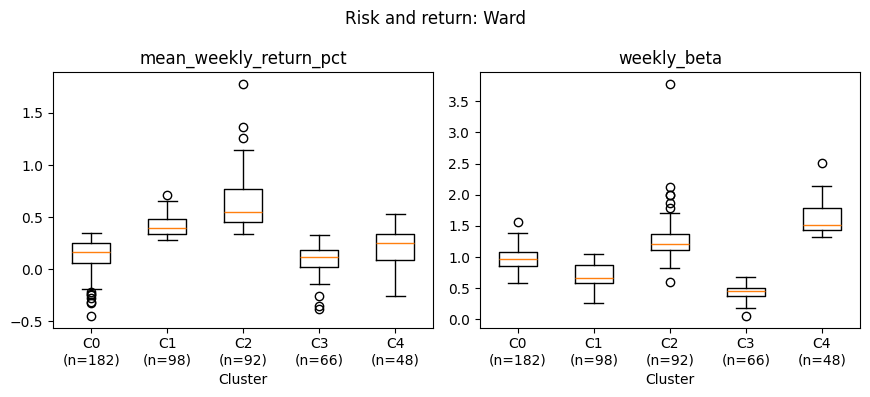

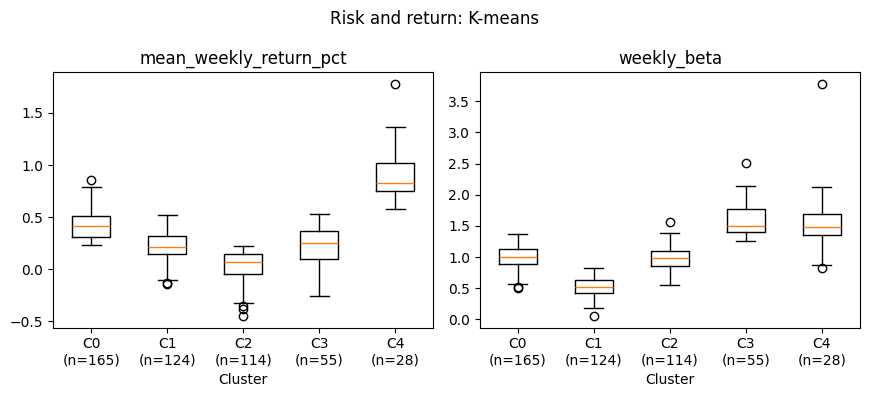

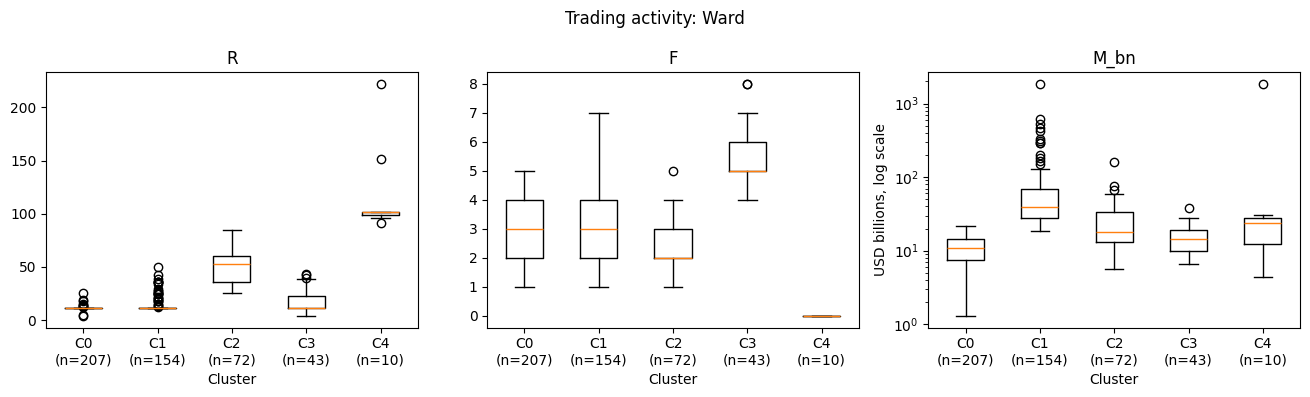

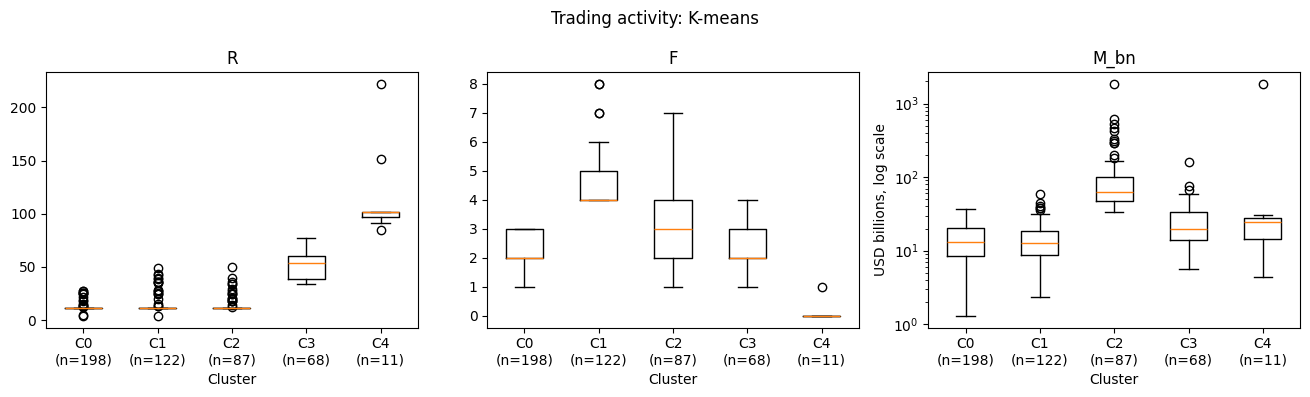

In [287]:
# Boxplots by cluster in original units (one figure per solution)
def boxplots(col):
    f = FEATS[col.split("_")[0]]
    clusters = sorted(out[col].unique())
    fig, ax = plt.subplots(1, len(f), figsize=(4.4 * len(f), 4))
    for a, feat in zip(np.atleast_1d(ax), f):
        data = [out.loc[out[col] == c, feat].values for c in clusters]
        a.boxplot(data)
        a.set_xticklabels([f"C{c}\n(n={len(d)})" for c, d in zip(clusters, data)])
        a.set_title(feat); a.set_xlabel("Cluster")
        if feat == "M_bn":
            a.set_yscale("log"); a.set_ylabel("USD billions, log scale")
    fig.suptitle(TITLE[col])
    plt.tight_layout()
    plt.savefig(f"outputs/figures/fig_boxplots_{col}.png", dpi=200)
    plt.show()

for col in SOL:
    boxplots(col)

PCA explained variance ratio: [0.458 0.336] | cumulative: 0.794

PCA loadings (signs are arbitrary):
            PC1    PC2
R        0.711  0.023
F       -0.650  0.402
log1p_M  0.268  0.915


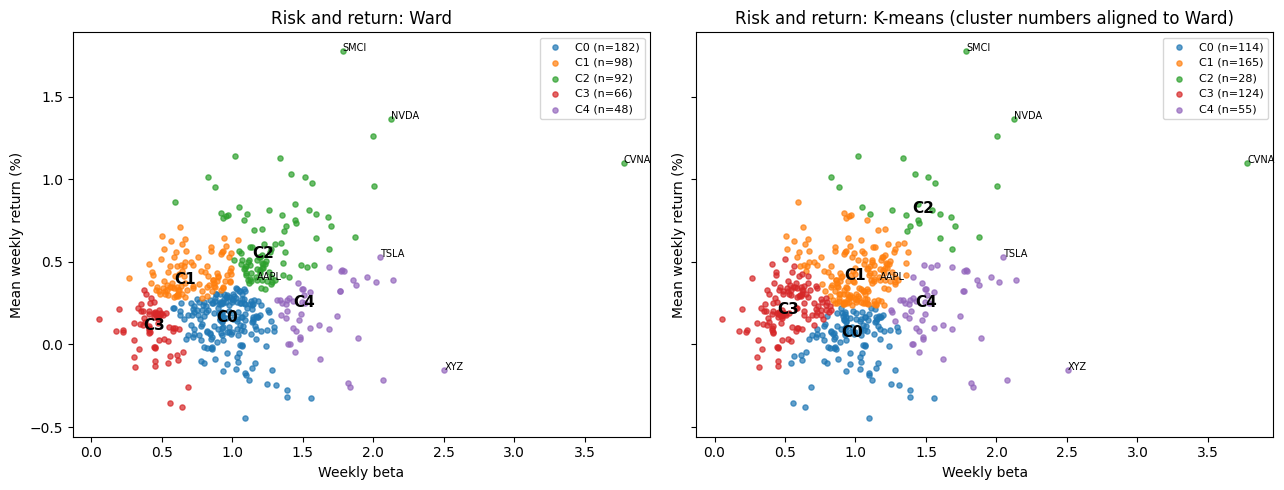

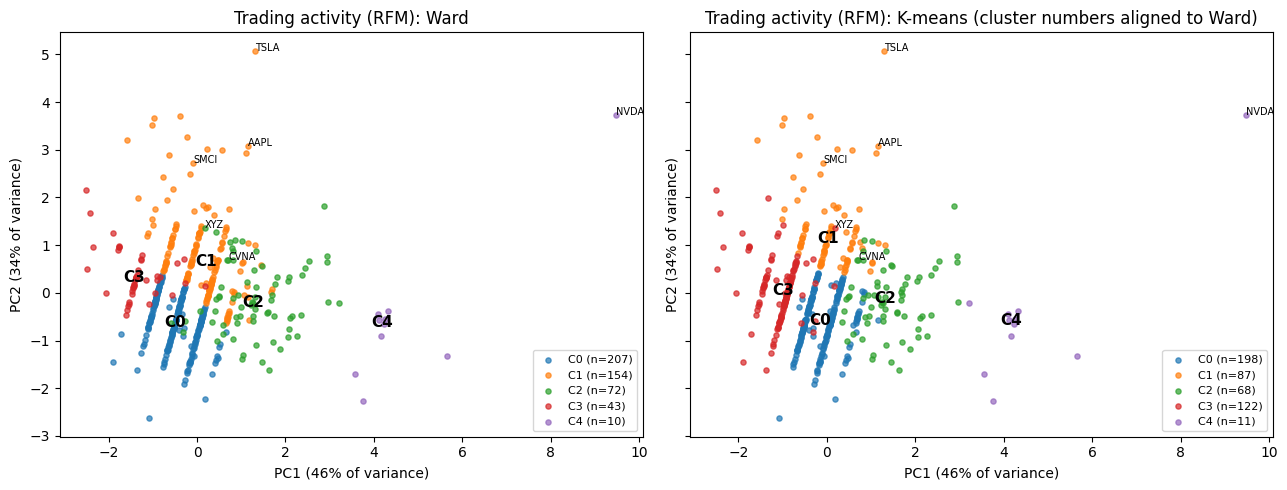

In [288]:
# Clustering profiles visualisations
pca = PCA(n_components=2, random_state=0).fit(Xs["act"].values)
print("PCA explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| cumulative:", round(float(pca.explained_variance_ratio_.sum()), 3))
loadings = pd.DataFrame(pca.components_.T, index=Xs["act"].columns, columns=["PC1", "PC2"])
print("\nPCA loadings (signs are arbitrary):\n", loadings.round(3))
pcs = pd.DataFrame(pca.transform(Xs["act"].values), index=Xs["act"].index, columns=["PC1", "PC2"])

def align_labels(ref, other):
    """Re-number `other` to best match `ref` (Hungarian method). Display only: memberships do not change."""
    ct = pd.crosstab(ref, other)
    r, c = linear_sum_assignment(-ct.values)
    mapping = {ct.columns[ci]: ct.index[ri] for ri, ci in zip(r, c)}
    nxt = int(max(ref)) + 1
    for lab in ct.columns:
        if lab not in mapping:
            mapping[lab] = nxt; nxt += 1
    return other.map(mapping)

aligned = {m: align_labels(out[f"{m}_ward"], out[f"{m}_kmeans"]) for m in ("rr", "act")}
NOTABLE = ["TSLA", "NVDA", "CVNA", "SMCI", "XYZ", "AAPL"]      # annotated if present

def scatter_pair(m, xy, xlabel, ylabel, fname):
    fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
    panels = [("Ward", out[f"{m}_ward"]), ("K-means (cluster numbers aligned to Ward)", aligned[m])]
    for a, (alg, labs) in zip(ax, panels):
        for c in sorted(labs.unique()):
            idx = labs == c
            a.scatter(xy.loc[idx].iloc[:, 0], xy.loc[idx].iloc[:, 1], s=14, alpha=0.7, label=f"C{c} (n={int(idx.sum())})")
            cx, cy = xy.loc[idx].median()
            a.text(cx, cy, f"C{c}", fontsize=11, weight="bold", ha="center", va="center")
        for t in NOTABLE:
            if t in xy.index:
                a.annotate(t, tuple(xy.loc[t].values), fontsize=7)
        a.set_title(f"{NAMES[m]}: {alg}"); a.set_xlabel(xlabel); a.set_ylabel(ylabel); a.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"outputs/figures/{fname}", dpi=200)
    plt.show()

xy_rr = pd.DataFrame({"beta": out["weekly_beta"], "ret": out["mean_weekly_return_pct"]})
scatter_pair("rr", xy_rr, "Weekly beta", "Mean weekly return (%)", "fig_clusters_riskreturn.png")
scatter_pair("act", pcs,
             f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
             f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)", "fig_clusters_activity_pca.png")

In [289]:
# Compare the two algorithms on the same shares
rows = []
for m in ("rr", "act"):
    w, k, ka = out[f"{m}_ward"], out[f"{m}_kmeans"], aligned[m]
    rows.append({
        "matrix": NAMES[m], "k_ward": w.nunique(), "k_kmeans": k.nunique(),
        "adjusted_rand_index": adjusted_rand_score(w, k),
        "share_in_matching_cluster_after_alignment": float((w == ka).mean()),
        "silhouette_ward": silhouette_score(Xs[m].values, w),
        "silhouette_kmeans": silhouette_score(Xs[m].values, k),
        "sizes_ward": sorted(w.value_counts().tolist(), reverse=True),
        "sizes_kmeans": sorted(k.value_counts().tolist(), reverse=True),
    })
cmp = pd.DataFrame(rows)
print(cmp.round(3).T.to_string())
cmp.to_csv("outputs/algorithm_comparison.csv", index=False)

for m in ("rr", "act"):
    print(f"\n{NAMES[m]}: rows = Ward cluster, columns = K-means cluster (aligned numbering)")
    print(pd.crosstab(out[f"{m}_ward"], aligned[m], rownames=["Ward"], colnames=["K-means"]))

                                                                 0                       1
matrix                                             Risk and return  Trading activity (RFM)
k_ward                                                           5                       5
k_kmeans                                                         5                       5
adjusted_rand_index                                          0.329                   0.401
share_in_matching_cluster_after_alignment                    0.609                    0.71
silhouette_ward                                              0.304                   0.305
silhouette_kmeans                                            0.338                   0.358
sizes_ward                                   [182, 98, 92, 66, 48]  [207, 154, 72, 43, 10]
sizes_kmeans                               [165, 124, 114, 55, 28]  [198, 122, 87, 68, 11]

Risk and return: rows = Ward cluster, columns = K-means cluster (aligned numbering)
K-mea

In [290]:
# Preview for Task 3.2.1: do risk/return clusters and activity clusters agree?
print("Adjusted Rand index between the two matrices' solutions (near 0 = unrelated partitions):")
for a in ("rr_ward", "rr_kmeans"):
    for b in ("act_ward", "act_kmeans"):
        print(f"  {a} vs {b}: {adjusted_rand_score(out[a], out[b]):.3f}")

Adjusted Rand index between the two matrices' solutions (near 0 = unrelated partitions):
  rr_ward vs act_ward: 0.043
  rr_ward vs act_kmeans: 0.030
  rr_kmeans vs act_ward: 0.016
  rr_kmeans vs act_kmeans: 0.013


## Task 2.5 RFM sensitivity and correlated inputs

In [291]:
# Load
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_score
from scipy.optimize import linear_sum_assignment

os.makedirs("outputs/figures", exist_ok=True)

out = pd.read_csv("outputs/cluster_assignments_baseline.csv", index_col=0)
X_raw = pd.read_csv("outputs/X_activity_raw.csv", index_col=0)        # R (or log1p_R), F, log1p_M
X_sc = pd.read_csv("outputs/X_activity_scaled.csv", index_col=0)
orig = pd.read_csv("outputs/features_common_set_original_units.csv", index_col=0)
meta = json.load(open("outputs/clustering_metadata.json"))
K = meta["K_CHOICE"]["act_ward"]                                      # the selected Ward RFM cluster count

assert out.index.equals(X_raw.index) and out.index.equals(X_sc.index) and out.index.equals(orig.index)
print("Shares:", len(out), "| activity features:", list(X_raw.columns), "| selected Ward k:", K)

Shares: 486 | activity features: ['R', 'F', 'log1p_M'] | selected Ward k: 5


Pearson:
              R      F  log1p_M
R        1.000 -0.346    0.152
F       -0.346  1.000    0.013
log1p_M  0.152  0.013    1.000 

Spearman:
              R      F  log1p_M
R        1.000 -0.196    0.137
F       -0.196  1.000   -0.048
log1p_M  0.137 -0.048    1.000


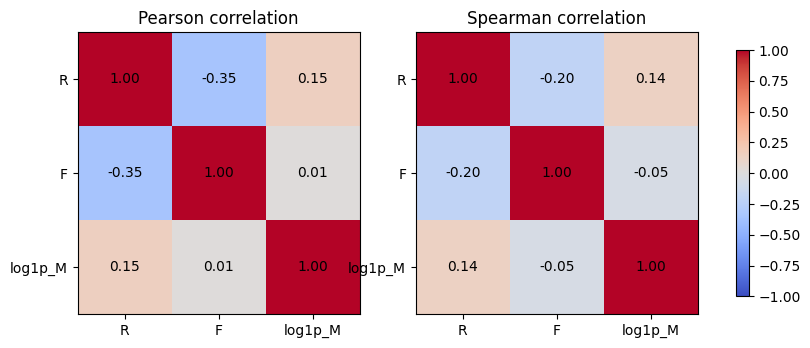

In [292]:
# 2.5.1 correlations (Pearson, plus Spearman because R has a spike and F is a small-integer count)
pear = X_raw.corr(method="pearson")
spear = X_raw.corr(method="spearman")
print("Pearson:\n", pear.round(3), "\n\nSpearman:\n", spear.round(3))
pear.round(4).to_csv("outputs/rfm_correlations_pearson.csv")
spear.round(4).to_csv("outputs/rfm_correlations_spearman.csv")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, cm) in zip(ax, [("Pearson", pear), ("Spearman", spear)]):
    im = a.imshow(cm.values, vmin=-1, vmax=1, cmap="coolwarm")
    a.set_xticks(range(len(cm))); a.set_xticklabels(cm.columns)
    a.set_yticks(range(len(cm))); a.set_yticklabels(cm.columns)
    for i in range(len(cm)):
        for j in range(len(cm)):
            a.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center")
    a.set_title(f"{name} correlation")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.savefig("outputs/figures/fig_rfm_correlations.png", dpi=200, bbox_inches="tight")
plt.show()

In [293]:
# How much information is shared? (eigenvalues of the correlation matrix)
# After standardisation each feature has variance 1, but correlated features overlap: a shared
# component is counted more than once in Euclidean distance. An eigenvalue above 1 means a shared factor.
eig = np.sort(np.linalg.eigvalsh(pear.values))[::-1]
print("Eigenvalues:", eig.round(3), "| share of total variance:", (eig / eig.sum()).round(3))

Eigenvalues: [1.374 1.009 0.617] | share of total variance: [0.458 0.336 0.206]


In [294]:
# What do the clusters actually separate? eta-squared per standardised feature
def eta_squared(Xs, labels):
    grand = Xs.mean()
    total = ((Xs - grand) ** 2).sum()
    between = sum(len(d) * (d.mean() - grand) ** 2 for _, d in Xs.groupby(labels))
    return between / total

eta = pd.DataFrame({sol: eta_squared(X_sc, out[sol]) for sol in ["act_ward", "act_kmeans"]})
print("\nShare of each feature's variance explained by the baseline clusters:\n", eta.round(3))
eta.round(4).to_csv("outputs/rfm_eta_squared_baseline.csv")


Share of each feature's variance explained by the baseline clusters:
          act_ward  act_kmeans
R           0.824       0.825
F           0.422       0.603
log1p_M     0.526       0.512


In [295]:
# 2.5.2 Remove Monetary: same shares, same k, standardise AFRESH
def relabel_by_size(lab):
    order = pd.Series(lab).value_counts().index
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping[v] for v in lab])

def align_labels(ref, other):
    """Re-number `other` to best match `ref` (display only). ARI itself does not need this."""
    ct = pd.crosstab(ref, other)
    r, c = linear_sum_assignment(-ct.values)
    mapping = {ct.columns[ci]: ct.index[ri] for ri, ci in zip(r, c)}
    nxt = int(max(ref)) + 1
    for lab in ct.columns:
        if lab not in mapping:
            mapping[lab] = nxt; nxt += 1
    return other.map(mapping)

cols_noM = [c for c in X_raw.columns if c != "log1p_M"]
Xr = pd.DataFrame(StandardScaler().fit_transform(X_raw[cols_noM]), index=X_raw.index, columns=cols_noM)

red = pd.Series(relabel_by_size(AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xr.values)),
                index=Xr.index, name="act_ward_RF_only")
base = out["act_ward"]
red_aligned = align_labels(base, red)

ari = adjusted_rand_score(base, red)
print(f"\nFeatures used: {cols_noM} | k = {K} | shares = {len(Xr)}")
print(f"Adjusted Rand index, baseline (R,F,M) vs reduced (R,F): {ari:.3f}")
print(f"Share of shares in the matching cluster after alignment: {(base == red_aligned).mean():.3f}")
print(f"Silhouette of the reduced solution (in its own R,F space): {silhouette_score(Xr.values, red):.3f}")
print("\nRows = baseline Ward cluster, columns = reduced cluster (numbering aligned to baseline):")
print(pd.crosstab(base, red_aligned, rownames=["baseline"], colnames=["R,F only"]))


Features used: ['R', 'F'] | k = 5 | shares = 486
Adjusted Rand index, baseline (R,F,M) vs reduced (R,F): 0.335
Share of shares in the matching cluster after alignment: 0.654
Silhouette of the reduced solution (in its own R,F space): 0.593

Rows = baseline Ward cluster, columns = reduced cluster (numbering aligned to baseline):
R,F only    0   1   2   3   4
baseline                     
0         139  66   0   2   0
1          69  59   9  17   0
2           2   0  69   1   0
3           1   0   1  41   0
4           0   0   0   0  10


In [296]:
# Do the clusters differ in traded value? (liquidity proxy, not spread or price impact)
tv = pd.DataFrame({"M_bn": orig["M"] / 1e9, "log1p_M": np.log1p(orig["M"])})

def tv_profile(labels):
    g = tv.groupby(labels)["M_bn"]
    return pd.concat([g.size().rename("n"), g.median().rename("median_M_bn"),
                      g.quantile(0.25).rename("q1_M_bn"), g.quantile(0.75).rename("q3_M_bn")], axis=1)

print("\nTraded value by BASELINE cluster (USD bn, 60 sessions):\n", tv_profile(base).round(2).to_string())
print("\nTraded value by REDUCED (R,F only) cluster, numbering aligned to baseline:\n", tv_profile(red_aligned).round(2).to_string())

eta_M = pd.Series({"baseline (R,F,M)": eta_squared(tv[["log1p_M"]], base)["log1p_M"],
                   "reduced (R,F only)": eta_squared(tv[["log1p_M"]], red_aligned)["log1p_M"]})
print("\nShare of log1p(M) variance explained by cluster membership:\n", eta_M.round(3))


Traded value by BASELINE cluster (USD bn, 60 sessions):
             n  median_M_bn  q1_M_bn  q3_M_bn
act_ward                                    
0         207        10.79     7.53    14.56
1         154        39.70    28.22    68.39
2          72        17.68    13.25    33.73
3          43        14.43    10.02    19.35
4          10        23.79    12.51    27.67

Traded value by REDUCED (R,F only) cluster, numbering aligned to baseline:
                     n  median_M_bn  q1_M_bn  q3_M_bn
act_ward_RF_only                                    
0                 211        14.71     9.03    27.89
1                 125        17.70    10.52    31.80
2                  79        20.13    13.97    35.51
3                  61        16.89    10.88    40.52
4                  10        23.79    12.51    27.67

Share of log1p(M) variance explained by cluster membership:
 baseline (R,F,M)      0.526
reduced (R,F only)    0.022
dtype: float64


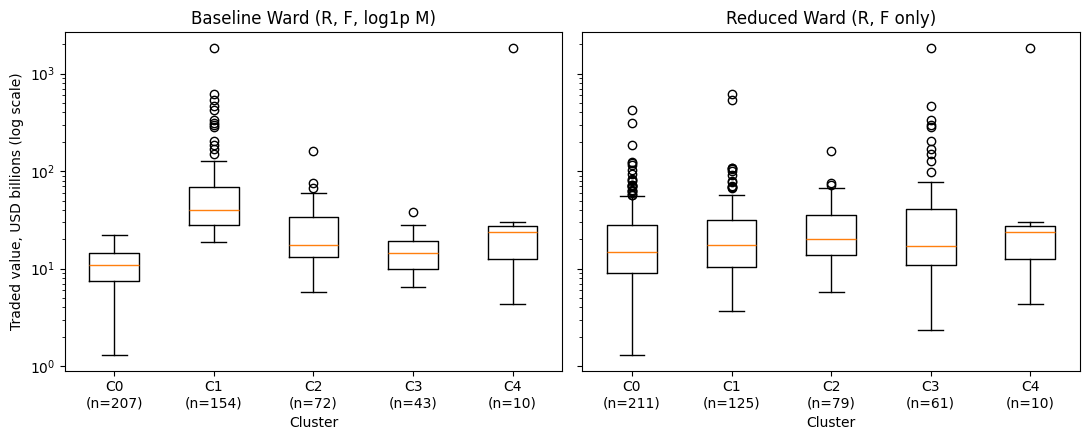

In [297]:
# Figure, traded value by cluster before and after removing M
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for a, (title, labs) in zip(ax, [("Baseline Ward (R, F, log1p M)", base), ("Reduced Ward (R, F only)", red_aligned)]):
    clusters = sorted(labs.unique())
    data = [tv.loc[labs == c, "M_bn"].values for c in clusters]
    a.boxplot(data)
    a.set_xticklabels([f"C{c}\n(n={len(d)})" for c, d in zip(clusters, data)])
    a.set_yscale("log"); a.set_title(title); a.set_xlabel("Cluster")
ax[0].set_ylabel("Traded value, USD billions (log scale)")
plt.tight_layout()
plt.savefig("outputs/figures/fig_monetary_removal.png", dpi=200)
plt.show()

In [298]:
# Save results and metadata
res = out[["company", "sector"]].copy()
res["act_ward_baseline"] = base
res["act_ward_RF_only"] = red
res["act_ward_RF_only_aligned_to_baseline"] = red_aligned
res.to_csv("outputs/act_ward_RF_only_assignments.csv")

json.dump({"selected_k": int(K), "features_reduced": cols_noM,
           "adjusted_rand_index": float(ari),
           "share_matching_after_alignment": float((base == red_aligned).mean()),
           "standardisation": "reduced matrix standardised afresh (StandardScaler)",
           "calculation_version": "v1"},
          open("outputs/monetary_removal_metadata.json", "w"), indent=2)

## Task 3.2.1 Sector composition and cross-solution comparison

In [299]:
# Load
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import chi2_contingency
from sklearn.metrics import adjusted_rand_score

os.makedirs("outputs/figures", exist_ok=True)

out = pd.read_csv("outputs/cluster_assignments_baseline.csv", index_col=0)
SOL = ["rr_ward", "rr_kmeans", "act_ward", "act_kmeans"]
TITLE = {"rr_ward": "Risk and return: Ward", "rr_kmeans": "Risk and return: K-means",
         "act_ward": "Trading activity: Ward", "act_kmeans": "Trading activity: K-means"}

overall = out["sector"].value_counts(normalize=True)
sector_order = overall.index.tolist()
cmap = plt.get_cmap("tab20")
colours = {s: cmap(i) for i, s in enumerate(sector_order)}
print("Shares:", len(out), "| sectors:", len(sector_order))
print("Overall sector mix (%):\n", (overall * 100).round(1).to_string())

Shares: 486 | sectors: 11
Overall sector mix (%):
 sector
Industrials               16.0
Financials                15.2
Information Technology    15.2
Health Care               11.9
Consumer Discretionary     9.7
Consumer Staples           6.6
Utilities                  6.2
Real Estate                6.2
Materials                  4.7
Energy                     4.1
Communication Services     4.1


In [300]:
# Sector counts and "lift" per cluster
# lift = (sector's share inside the cluster) / (sector's share in the whole sample). 1.0 = same as overall.
def sector_tables(sol):
    ct = pd.crosstab(out[sol], out["sector"]).reindex(columns=sector_order, fill_value=0)
    share = ct.div(ct.sum(axis=1), axis=0)
    lift = share.div(overall, axis=1)
    return ct, share, lift

for sol in SOL:
    ct, share, lift = sector_tables(sol)
    print(f"\n{TITLE[sol]}: counts")
    print(ct.to_string())
    print(f"{TITLE[sol]}: lift")
    print(lift.round(2).to_string())
    ct.to_csv(f"outputs/sector_counts_{sol}.csv")
    lift.round(3).to_csv(f"outputs/sector_lift_{sol}.csv")


Risk and return: Ward: counts
sector   Industrials  Financials  Information Technology  Health Care  Consumer Discretionary  Consumer Staples  Utilities  Real Estate  Materials  Energy  Communication Services
rr_ward                                                                                                                                                                           
0                 40          26                      20           25                      17                 5          5           23         14       0                       7
1                 11          28                       2            8                       9                 5          8            3          3      16                       5
2                 21          13                      29            2                      11                 0          1            3          3       4                       5
3                  2           2                       0           19     

In [301]:
# How strongly is sector associated with each solution? (descriptive; interpret with care)
def cramers_v(ct):
    chi2, p, dof, expected = chi2_contingency(ct.values)
    n = ct.values.sum()
    k = min(ct.shape) - 1
    return float(np.sqrt(chi2 / (n * k))), float(p), float((expected < 5).mean())

rows = []
for sol in SOL:
    ct, _, _ = sector_tables(sol)
    v, p, low = cramers_v(ct)
    rows.append({"solution": TITLE[sol], "cramers_v": v, "chi2_p_value": p, "share_of_cells_expected_below_5": low})
assoc = pd.DataFrame(rows)
print(assoc.round(4).to_string(index=False))
print("\nNote: with many small cells the chi-square p-value is approximate, and Cramer's V is biased upwards in small samples.")
assoc.round(4).to_csv("outputs/sector_association.csv", index=False)

                 solution  cramers_v  chi2_p_value  share_of_cells_expected_below_5
    Risk and return: Ward     0.4272        0.0000                           0.3455
 Risk and return: K-means     0.3626        0.0000                           0.3455
   Trading activity: Ward     0.2117        0.0000                           0.4364
Trading activity: K-means     0.2083        0.0001                           0.3636

Note: with many small cells the chi-square p-value is approximate, and Cramer's V is biased upwards in small samples.


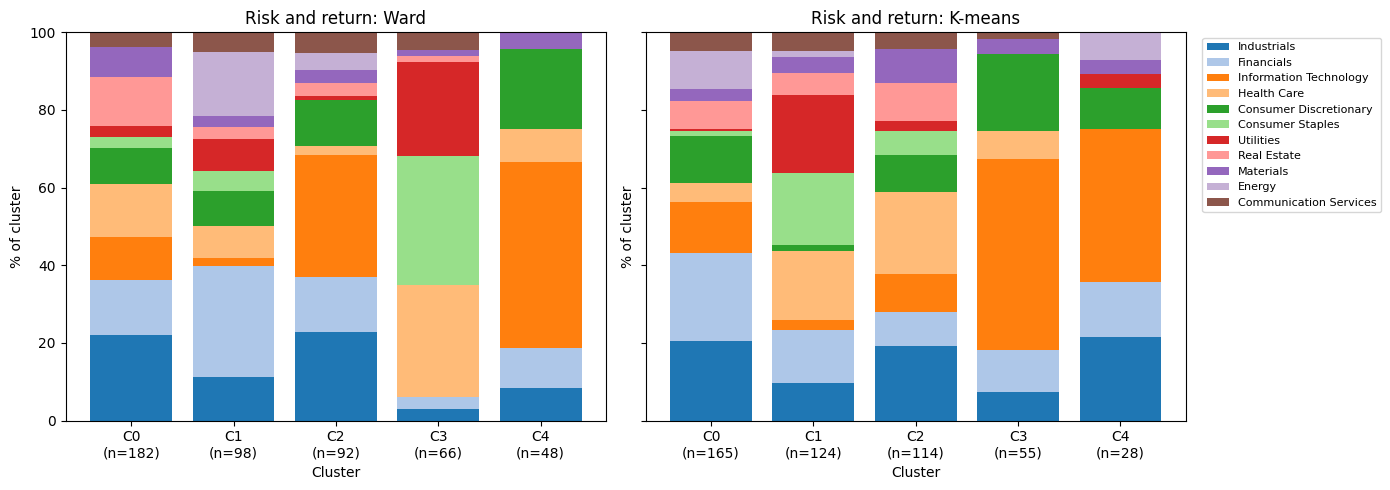

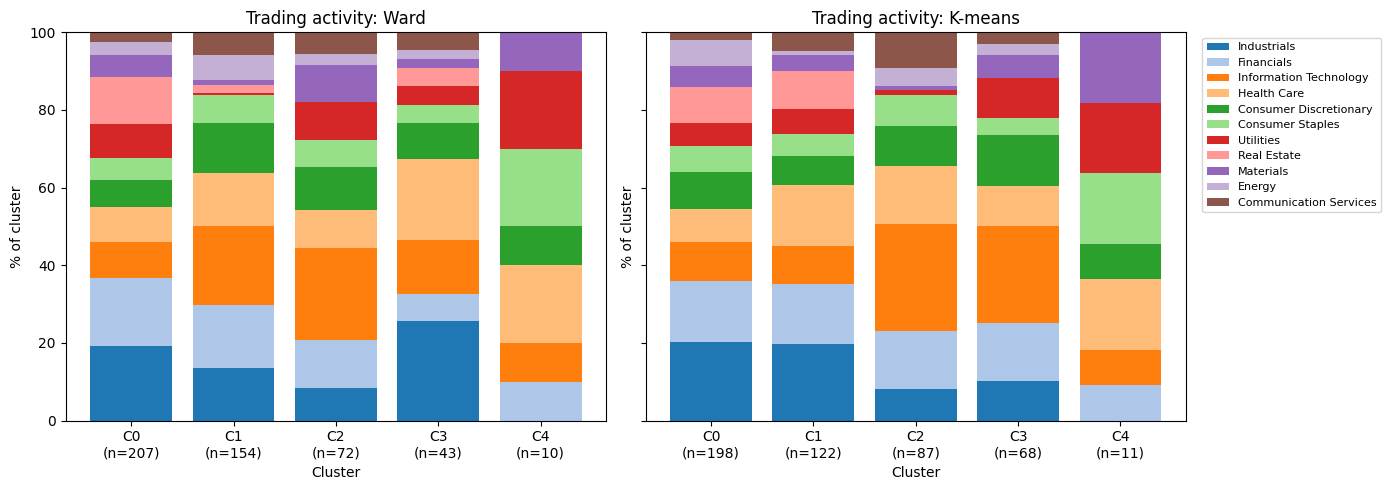

In [302]:
# Stacked sector composition per cluster (one figure per matrix, Ward and K-means side by side)
def sector_bars(m):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for a, sol in zip(ax, [f"{m}_ward", f"{m}_kmeans"]):
        ct, share, _ = sector_tables(sol)
        x = np.arange(len(ct))
        bottom = np.zeros(len(ct))
        for s in sector_order:
            a.bar(x, share[s].values * 100, bottom=bottom, color=colours[s], label=s)
            bottom += share[s].values * 100
        a.set_xticks(x)
        a.set_xticklabels([f"C{c}\n(n={n})" for c, n in zip(ct.index, ct.sum(axis=1))])
        a.set_title(TITLE[sol]); a.set_ylabel("% of cluster"); a.set_xlabel("Cluster")
    ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.savefig(f"outputs/figures/fig_sector_composition_{m}.png", dpi=200, bbox_inches="tight")
    plt.show()

sector_bars("rr")
sector_bars("act")

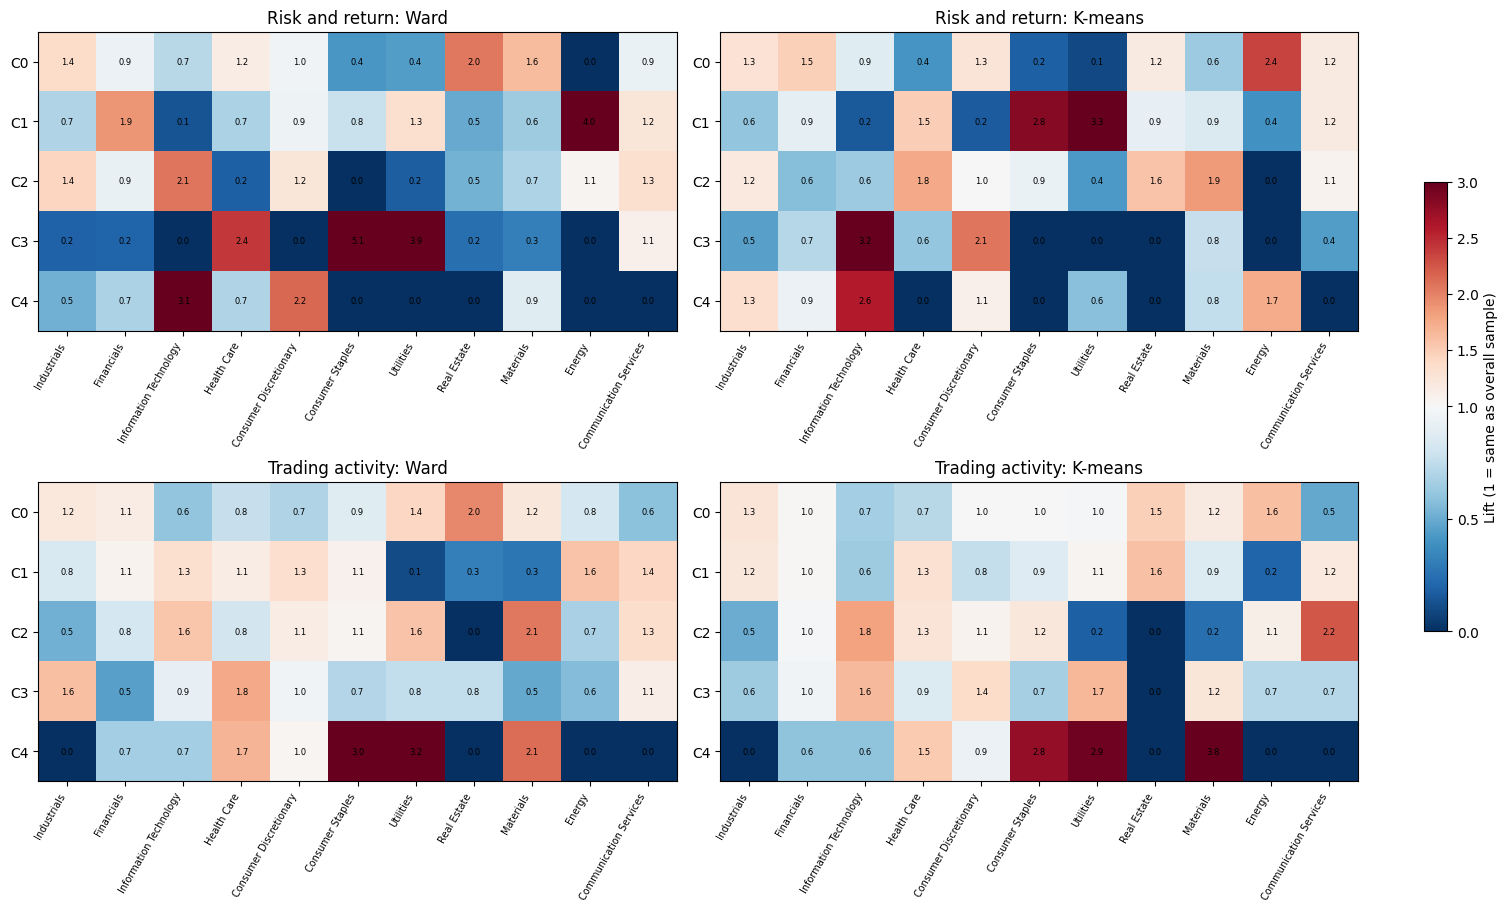

In [303]:
# Lift heatmaps (which sectors are over- or under-represented in each cluster)
fig, ax = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for a, sol in zip(ax.ravel(), SOL):
    _, _, lift = sector_tables(sol)
    im = a.imshow(lift.values, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=0, vcenter=1, vmax=3), aspect="auto")
    a.set_xticks(range(len(sector_order))); a.set_xticklabels(sector_order, rotation=60, ha="right", fontsize=7)
    a.set_yticks(range(len(lift))); a.set_yticklabels([f"C{c}" for c in lift.index])
    for i in range(lift.shape[0]):
        for j in range(lift.shape[1]):
            a.text(j, i, f"{lift.values[i, j]:.1f}", ha="center", va="center", fontsize=6)
    a.set_title(TITLE[sol])
fig.colorbar(im, ax=ax, shrink=0.6, label="Lift (1 = same as overall sample)")
plt.savefig("outputs/figures/fig_sector_lift.png", dpi=200, bbox_inches="tight")
plt.show()

In [304]:
# Headline over-represented sectors per cluster (only sectors with at least 5 shares in the cluster)
for sol in SOL:
    ct, _, lift = sector_tables(sol)
    print(f"\n{TITLE[sol]}")
    for c in ct.index:
        cand = lift.loc[c][ct.loc[c] >= 5].sort_values(ascending=False).head(2)
        print(f"  C{c} (n={int(ct.loc[c].sum())}): " + ", ".join(f"{s} (lift {v:.2f})" for s, v in cand.items()))


Risk and return: Ward
  C0 (n=182): Real Estate (lift 2.05), Materials (lift 1.63)
  C1 (n=98): Energy (lift 3.97), Financials (lift 1.88)
  C2 (n=92): Information Technology (lift 2.07), Industrials (lift 1.42)
  C3 (n=66): Consumer Staples (lift 5.06), Utilities (lift 3.93)
  C4 (n=48): Information Technology (lift 3.15), Consumer Discretionary (lift 2.15)

Risk and return: K-means
  C0 (n=165): Energy (lift 2.36), Financials (lift 1.47)
  C1 (n=124): Utilities (lift 3.27), Consumer Staples (lift 2.82)
  C2 (n=114): Materials (lift 1.85), Health Care (lift 1.76)
  C3 (n=55): Information Technology (lift 3.22), Consumer Discretionary (lift 2.07)
  C4 (n=28): Information Technology (lift 2.58), Industrials (lift 1.34)

Trading activity: Ward
  C0 (n=207): Real Estate (lift 1.96), Utilities (lift 1.41)
  C1 (n=154): Energy (lift 1.58), Communication Services (lift 1.42)
  C2 (n=72): Materials (lift 2.05), Utilities (lift 1.58)
  C3 (n=43): Health Care (lift 1.75), Industrials (lift 1.5


rr_ward vs act_ward: ARI = 0.043 | Cramer's V = 0.162 | chi2 p = 1.51e-05
Trading activity: Ward    0   1   2   3  4
Risk and return: Ward                     
0                       100  39  28  15  0
1                        47  35   7   6  3
2                        24  37  18  12  1
3                        23  23  11   4  5
4                        13  20   8   6  1

rr_kmeans vs act_kmeans: ARI = 0.013 | Cramer's V = 0.109 | chi2 p = 0.111
Trading activity: K-means   0   1   2   3  4
Risk and return: K-means                    
0                          76  41  27  20  1
1                          46  30  25  16  7
2                          51  32  13  17  1
3                          17  13  15   9  1
4                           8   6   7   6  1


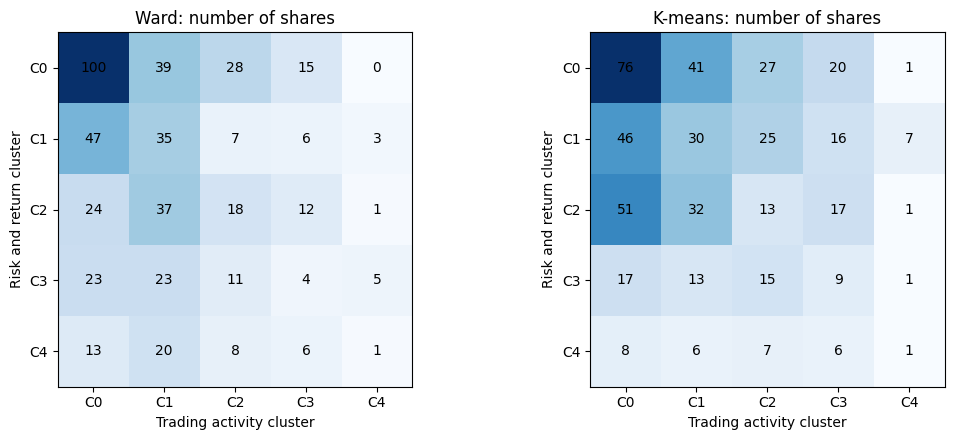

In [305]:
# Do risk/return clusters line up with activity clusters? (cluster-by-cluster cross-tab)
for a_, b_ in [("rr_ward", "act_ward"), ("rr_kmeans", "act_kmeans")]:
    ct = pd.crosstab(out[a_], out[b_], rownames=[TITLE[a_]], colnames=[TITLE[b_]])
    v, p, low = cramers_v(ct)
    print(f"\n{a_} vs {b_}: ARI = {adjusted_rand_score(out[a_], out[b_]):.3f} | Cramer's V = {v:.3f} | chi2 p = {p:.3g}")
    print(ct.to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (a_, b_) in zip(ax, [("rr_ward", "act_ward"), ("rr_kmeans", "act_kmeans")]):
    ct = pd.crosstab(out[a_], out[b_])
    a.imshow(ct.values, cmap="Blues")
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            a.text(j, i, ct.values[i, j], ha="center", va="center")
    a.set_xticks(range(ct.shape[1])); a.set_xticklabels([f"C{c}" for c in ct.columns])
    a.set_yticks(range(ct.shape[0])); a.set_yticklabels([f"C{c}" for c in ct.index])
    a.set_xlabel("Trading activity cluster"); a.set_ylabel("Risk and return cluster")
    a.set_title(TITLE[a_].split(":")[1].strip() + ": number of shares")
plt.tight_layout()
plt.savefig("outputs/figures/fig_rr_vs_activity_crosstab.png", dpi=200)
plt.show()

In [306]:
import os
import json
import pandas as pd
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define base directory (Change this if your folder name is different)
BASE_DIR = "/content/drive/MyDrive/crm_cwk1"

# 3. Create necessary directories (exist_ok=True ensures NO existing data is overwritten)
os.makedirs(f"{BASE_DIR}/data/raw", exist_ok=True)
os.makedirs(f"{BASE_DIR}/data/clean", exist_ok=True)
os.makedirs(f"{BASE_DIR}/outputs", exist_ok=True)
os.makedirs(f"{BASE_DIR}/outputs/figures", exist_ok=True)
print("✅ Directories created/verified.")

# 4. Save Metadata Files
# Acquisition Metadata
acquisition_meta = {
    "wikipedia_url": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
    "retrieval_utc": "2024-11-22",
    "data_source": "yfinance (Yahoo Finance), auto_adjust=False, actions=True",
    "start_inclusive": "2021-01-01",
    "end_exclusive": "2025-01-01",
    "benchmark": "^GSPC",
    "n_tickers_requested": 503,
    "n_tickers_failed": 5,
    "failed_tickers": ["FDXF", "HONA", "Q", "SNDK", "VYLR"],
    "first_date_in_data": "2021-01-04",
    "last_date_in_data": "2024-12-31",
    "calculation_version": "v1"
}
with open(f"{BASE_DIR}/data/raw/acquisition_metadata.json", "w") as f:
    json.dump(acquisition_meta, f, indent=2)
print("✅ Saved acquisition_metadata.json")

# RFM Metadata
rfm_meta = {
    "observation_date": "2024-12-31",
    "window_first_session": "2024-10-07",
    "window_sessions": 60,
    "baseline_sessions": 20,
    "threshold_multiplier": 2.0,
    "event_rule": "volume > 2 x mean volume of preceding 20 sessions (current day excluded), strict inequality",
    "recency_basis": "calendar days to latest event in whole valid history",
    "n_shares_rfm_valid": 486,
    "calculation_version": "v1"
}
with open(f"{BASE_DIR}/outputs/rfm_metadata.json", "w") as f:
    json.dump(rfm_meta, f, indent=2)
print("✅ Saved rfm_metadata.json")

# Clustering Metadata
clustering_meta = {
    "seed": 42,
    "n_init": 10,
    "k_range": [2, 3, 4, 5, 6, 7, 8],
    "K_CHOICE": {"rr_ward": 5, "rr_kmeans": 5, "act_ward": 5, "act_kmeans": 5},
    "ward": "scipy/sklearn Ward linkage, Euclidean distance, standardised features",
    "label_convention": "cluster numbers ranked by size, 0 = largest",
    "calculation_version": "v1"
}
with open(f"{BASE_DIR}/outputs/clustering_metadata.json", "w") as f:
    json.dump(clustering_meta, f, indent=2)
print("✅ Saved clustering_metadata.json")

# 5. Save Requirements.txt
req_path = f"{BASE_DIR}/requirements.txt"
if not os.path.exists(req_path):
    with open(req_path, "w") as f:
        f.write("pandas>=2.2.3\nnumpy>=1.26.0\nyfinance>=0.2.66\nscikit-learn>=1.5.0\nmatplotlib>=3.9.0\nseaborn>=0.13.0\nrequests>=2.31.0\nlxml>=5.1.0\nhtml5lib>=1.1\n")
    print("✅ Saved requirements.txt")

# 6. Safely save Key CSVs (Checks if variables exist to prevent errors)
try:
    if 'excl' in locals() or 'excl' in globals():
        excl.to_csv(f"{BASE_DIR}/outputs/exclusion_log.csv", index=False)
        print("✅ Saved exclusion_log.csv")

    if 'included' in locals() or 'included' in globals():
        pd.Series(included, name="ticker").to_csv(f"{BASE_DIR}/outputs/included_tickers.csv", index=False)
        print("✅ Saved included_tickers.csv")

    if 'full' in locals() or 'full' in globals():
        full.to_csv(f"{BASE_DIR}/outputs/feature_table_all.csv", index=False)
        print("✅ Saved feature_table_all.csv")

    if 'common' in locals() or 'common' in globals():
        common.index.to_series().to_csv(f"{BASE_DIR}/outputs/common_valid_shares.csv", index=False)
        print("✅ Saved common_valid_shares.csv")

    if 'out' in locals() or 'out' in globals():
        out.to_csv(f"{BASE_DIR}/outputs/cluster_assignments_baseline.csv", index=False)
        print("✅ Saved cluster_assignments_baseline.csv")

    if 'Xs' in locals() or 'Xs' in globals():
        if 'rr' in Xs:
            Xs['rr'].to_csv(f"{BASE_DIR}/outputs/X_riskreturn_scaled.csv")
        if 'act' in Xs:
            Xs['act'].to_csv(f"{BASE_DIR}/outputs/X_activity_scaled.csv")
        print("✅ Saved scaled feature matrices")

    if 'orig' in locals() or 'orig' in globals():
        orig.to_csv(f"{BASE_DIR}/outputs/features_common_set_original_units.csv")
        print("✅ Saved features_common_set_original_units.csv")

except Exception as e:
    print(f"⚠️ Warning saving CSVs: {e}")
    print("Please ensure you have run all previous cells so the variables (excl, included, full, common, out, Xs, orig) are in memory.")

print("\n🎉 All necessary files and folders are ready in your Google Drive for GitHub commit!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Directories created/verified.
✅ Saved acquisition_metadata.json
✅ Saved rfm_metadata.json
✅ Saved clustering_metadata.json
✅ Saved exclusion_log.csv
✅ Saved included_tickers.csv
✅ Saved feature_table_all.csv
✅ Saved common_valid_shares.csv
✅ Saved cluster_assignments_baseline.csv
✅ Saved scaled feature matrices
✅ Saved features_common_set_original_units.csv

🎉 All necessary files and folders are ready in your Google Drive for GitHub commit!


## Package versions


In [307]:
import sys, importlib
pkgs = {"pandas": "pandas", "numpy": "numpy", "scipy": "scipy", "scikit-learn": "sklearn",
        "matplotlib": "matplotlib", "yfinance": "yfinance"}
lines = []
for name, mod in pkgs.items():
    lines.append(f"{name}=={importlib.import_module(mod).__version__}")
print("Python", sys.version.split()[0]); print("\n".join(lines))
open("requirements.txt", "w").write("\n".join(lines) + "\n")


Python 3.13.18
pandas==2.2.3
numpy==2.4.6
scipy==1.16.3
scikit-learn==1.6.1
matplotlib==3.10.0
yfinance==0.2.66


97